# Senior Data Scientist İçin Proje İstatistiği

Her konu aynı yapıda: **ne işe yarar → ne zaman kullanılır → kod → tuzak**. 🇩🇪 satırı Almanca Fachbegriff tanımıdır.

| Bölüm | Konular | Öncelik |
|---|---|---|
| A. Veriyi tanımak | 1–6: ölçek türleri, merkez, yayılım, şekil, aykırı değer, grafikler | ⭐⭐⭐ |
| B. Olasılık | 7–9: Bayes, dağılımlar, merkezi limit teoremi | ⭐⭐⭐ |
| C. Çıkarım | 10–12: örnekleme, güven aralığı, bootstrap | ⭐⭐⭐ |
| D. Testler | 13–19: p-değeri, t-testi, ANOVA, ki-kare, güç analizi, A/B, çoklu test | ⭐⭐⭐ |
| E. İlişki ve model | 20–23: korelasyon, Simpson, lineer ve lojistik regresyon | ⭐⭐⭐ |
| F. Model değerlendirme | 24–26: cross-validation, metrikler, data leakage | ⭐⭐⭐ |
| G. İleri konular | 27–30: Bayes A/B, zaman serisi, nedensellik, eksik veri | ⭐⭐ |
| H. Uygulama | 31–33: test seçim tablosu, raporlama, alıştırmalar | ⭐⭐⭐ |

**Kurulum:** `pip install numpy pandas scipy statsmodels scikit-learn matplotlib`

In [1]:
# Bibliotheken importieren
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Hinweise auf künftige API-Änderungen ausblenden
warnings.filterwarnings("ignore", category=FutureWarning)

# Reproduzierbarer Zufallsgenerator
rng = np.random.default_rng(42)

# Einheitlicher Diagrammstil
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.axisbelow": True})

## 0. Örnek veri
Sentetik bir e-ticaret müşteri tablosu üretiyoruz. Gerçek kuralları **biz belirlediğimiz için** istatistiksel yöntemlerin doğruyu bulup bulmadığını görebiliriz.

In [2]:
# Synthetische Kundendaten erzeugen
n_customers = 2000
customers = pd.DataFrame({
    "age": rng.integers(18, 70, n_customers),
    "channel": rng.choice(["Ads", "Organic", "Referral"], n_customers, p=[0.5, 0.3, 0.2]),
    "visits": rng.poisson(5, n_customers),
})
# Umsatz: rechtsschief, steigt mit Besuchen und Alter
customers["revenue"] = np.exp(3 + 0.08 * customers["visits"] + 0.005 * customers["age"]
                              + rng.normal(0, 0.5, n_customers)).round(2)
# Kündigung: Wahrscheinlichkeit sinkt mit mehr Besuchen
logit = 0.5 - 0.35 * customers["visits"] + 0.6 * customers["channel"].eq("Ads")
customers["churn"] = rng.binomial(1, 1 / (1 + np.exp(-logit)))
customers.head()

,age,channel,visits,revenue,churn
0,22,Ads,5,82.05,0
1,58,Ads,2,83.72,0
2,52,Ads,8,75.06,0
3,40,Ads,5,38.84,0
4,40,Organic,4,17.10,0


# A. Veriyi Tanımak
## 1. Değişken türleri (ölçek düzeyleri)
Hangi istatistiği ve testi kullanacağını **önce değişkenin türü** belirler.

| Tür | Örnek | Anlamlı özet |
|---|---|---|
| Nominal | kanal, ülke | frekans, mod |
| Ordinal | memnuniyet 1–5 | medyan, çeyreklikler |
| Interval | sıcaklık °C | ortalama, fark |
| Ratio | gelir, yaş | hepsi, oran dahil |

🇩🇪 **Skalenniveau:** legt fest, welche Rechenoperationen bei einer Variable sinnvoll sind.

**Tuzak:** Sayı gibi görünen her şey sayısal değildir (posta kodu, müşteri ID).

In [3]:
# Datentypen und Anzahl eindeutiger Werte prüfen
pd.DataFrame({"dtype": customers.dtypes.astype(str), "unique": customers.nunique()})

,dtype,unique
age,int64,52
channel,str,3
visits,int64,15
revenue,float64,1753
churn,int64,2


## 2. Merkezi eğilim
- **Ortalama:** tüm değerleri kullanır, aykırıya hassastır.
- **Medyan:** ortadaki değer, çarpık veride daha temsili.
- **Kırpılmış ortalama:** uçlardan belirli oranı atar.
- **Geometrik ortalama:** büyüme oranları ve log-normal veri için.

🇩🇪 **Lagemaß:** Kennzahl, die das Zentrum einer Verteilung beschreibt.

In [4]:
# Lagemaße für den Umsatz berechnen
revenue = customers["revenue"]
print(f"Mittelwert:            {revenue.mean():8.2f}")
print(f"Median:                {revenue.median():8.2f}")
print(f"Getrimmt (10 %):       {stats.trim_mean(revenue, 0.10):8.2f}")
print(f"Geometrisches Mittel:  {stats.gmean(revenue):8.2f}")

# Effekt eines einzigen extremen Werts
with_outlier = np.append(revenue.to_numpy(), 1_000_000)
print(f"Mit Ausreißer -> Mittelwert: {with_outlier.mean():.2f}, Median: {np.median(with_outlier):.2f}")

Mittelwert:               43.23
Median:                   36.97
Getrimmt (10 %):          39.80
Geometrisches Mittel:     37.35
Mit Ausreißer -> Mittelwert: 542.96, Median: 36.97


In [5]:
# Wachstumsraten: geometrisches Mittel statt arithmetisches Mittel
growth = np.array([1.50, 0.50])  # +50 %, dann -50 %
print("Arithmetisch:", growth.mean(), "| Geometrisch:", round(stats.gmean(growth), 4))
print("Tatsächlicher Endwert von 100:", 100 * growth.prod())

Arithmetisch: 1.0 | Geometrisch: 0.866
Tatsächlicher Endwert von 100: 75.0


## 3. Yayılım
Aynı ortalamaya sahip iki grup çok farklı olabilir.

- **Varyans / standart sapma:** ortalamadan uzaklık. Örneklemde `ddof=1`.
- **IQR:** ortadaki %50'nin genişliği, sağlam ölçü.
- **MAD:** medyandan mutlak sapmaların medyanı.
- **CV:** std / ortalama; farklı ölçekleri karşılaştırır (pozitif ratio veride).

🇩🇪 **Streuungsmaß:** beschreibt, wie weit die Werte um das Zentrum verteilt sind.

**Tuzak:** `np.std` varsayılanı `ddof=0`, `pandas.std` varsayılanı `ddof=1`.

In [6]:
# Streuungsmaße
print("pandas std (ddof=1):", round(revenue.std(), 3))
print("numpy std  (ddof=0):", round(np.std(revenue.to_numpy()), 3))
print("Varianz:", round(revenue.var(), 2))
print("IQR:", round(stats.iqr(revenue), 2))
print("MAD:", round(stats.median_abs_deviation(revenue), 2))
print("Variationskoeffizient:", round(revenue.std() / revenue.mean(), 3))

pandas std (ddof=1): 25.112
numpy std  (ddof=0): 25.106
Varianz: 630.61
IQR: 27.96
MAD: 13.08
Variationskoeffizient: 0.581


## 4. Dağılımın şekli: çarpıklık ve basıklık
- **Skewness > 0:** sağa uzun kuyruk (gelir, fiyat, süre). Genelde ortalama > medyan.
- **Kurtosis (excess) > 0:** normalden ağır kuyruklar, uç değer riski.

Sağa çarpık pozitif veride **log dönüşümü** çoğu zaman simetri sağlar.

🇩🇪 **Schiefe:** Maß für die Asymmetrie. **Wölbung:** Maß für die Gewichtung der Ränder.

Original Schiefe:   1.78 | Exzess-Wölbung:   5.62
Log      Schiefe:   0.05 | Exzess-Wölbung:  -0.15


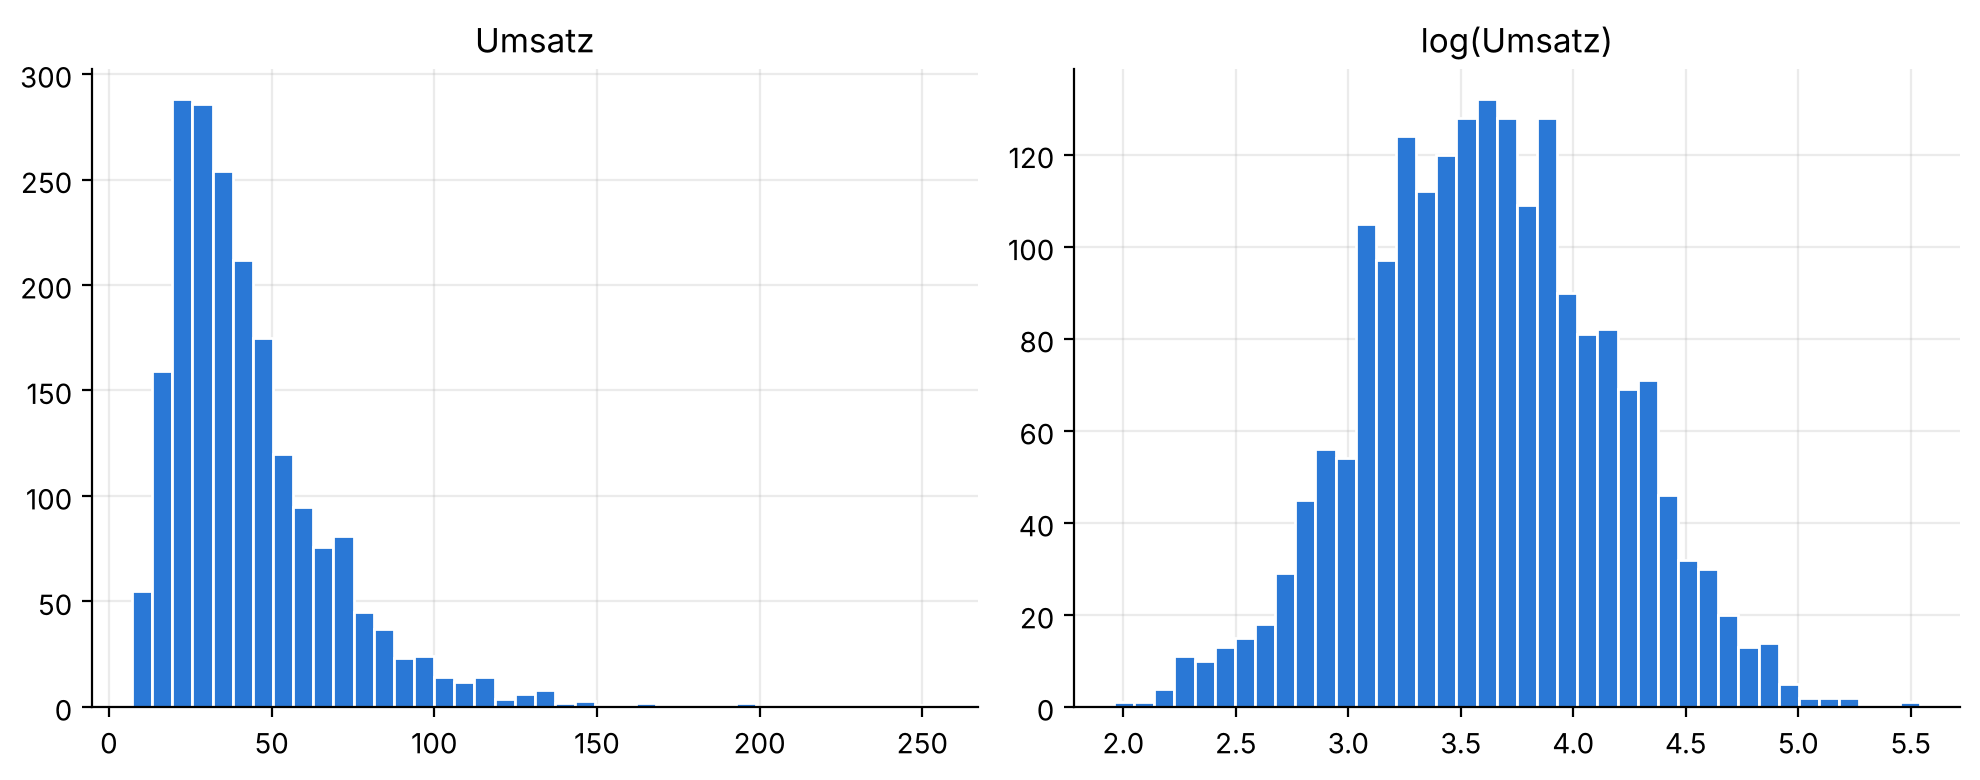

In [7]:
# Schiefe und Wölbung vor und nach der Log-Transformation
log_revenue = np.log(revenue)
for name, data in [("Original", revenue), ("Log", log_revenue)]:
    print(f"{name:8s} Schiefe: {stats.skew(data):6.2f} | Exzess-Wölbung: {stats.kurtosis(data):6.2f}")

fig, axes = plt.subplots(1, 2)
for ax, data, title in zip(axes, [revenue, log_revenue], ["Umsatz", "log(Umsatz)"]):
    ax.hist(data, bins=40, color=BLUE, edgecolor="white")
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 5. Aykırı değerler
| Yöntem | Kural | Ne zaman |
|---|---|---|
| Z-skoru | \|z\| > 3 | yaklaşık normal veri |
| IQR | Q1−1.5·IQR, Q3+1.5·IQR | genel amaçlı |
| Modifiye z (MAD) | \|M\| > 3.5 | çarpık / kirli veri |

🇩🇪 **Ausreißer:** Beobachtung, die ungewöhnlich weit von den übrigen Daten entfernt liegt.

**Karar ağacı:** Veri hatası mı? → düzelt/sil. Gerçek mi? → tut; log, sağlam model veya winsorizing düşün. Her kararı belgele.

In [8]:
def outlier_masks(x):
    """Vergleicht drei Methoden zur Ausreißererkennung."""
    x = np.asarray(x, dtype=float)
    z = np.abs(stats.zscore(x))
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    median = np.median(x)
    mad = np.median(np.abs(x - median))
    modified_z = 0.6745 * np.abs(x - median) / mad
    return {"z-Score": z > 3,
            "IQR": (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr),
            "Modifizierter z": modified_z > 3.5}

pd.DataFrame({name: {"Umsatz": m.sum(), "log(Umsatz)": outlier_masks(log_revenue)[name].sum()}
              for name, m in outlier_masks(revenue).items()})

,z-Score,IQR,Modifizierter z
Umsatz,30,88,58
log(Umsatz),4,7,1


## 6. Keşif grafikleri
- **Histogram:** şekil · **Boxplot:** gruplar arası karşılaştırma
- **ECDF:** "değerlerin yüzde kaçı x'in altında?" Bin seçimi gerektirmez.
- **Q-Q plot:** veri teorik dağılıma uyuyor mu? Noktalar çizgide ise uyum iyi.

🇩🇪 **Empirische Verteilungsfunktion:** Anteil der Beobachtungen, die höchstens x betragen.

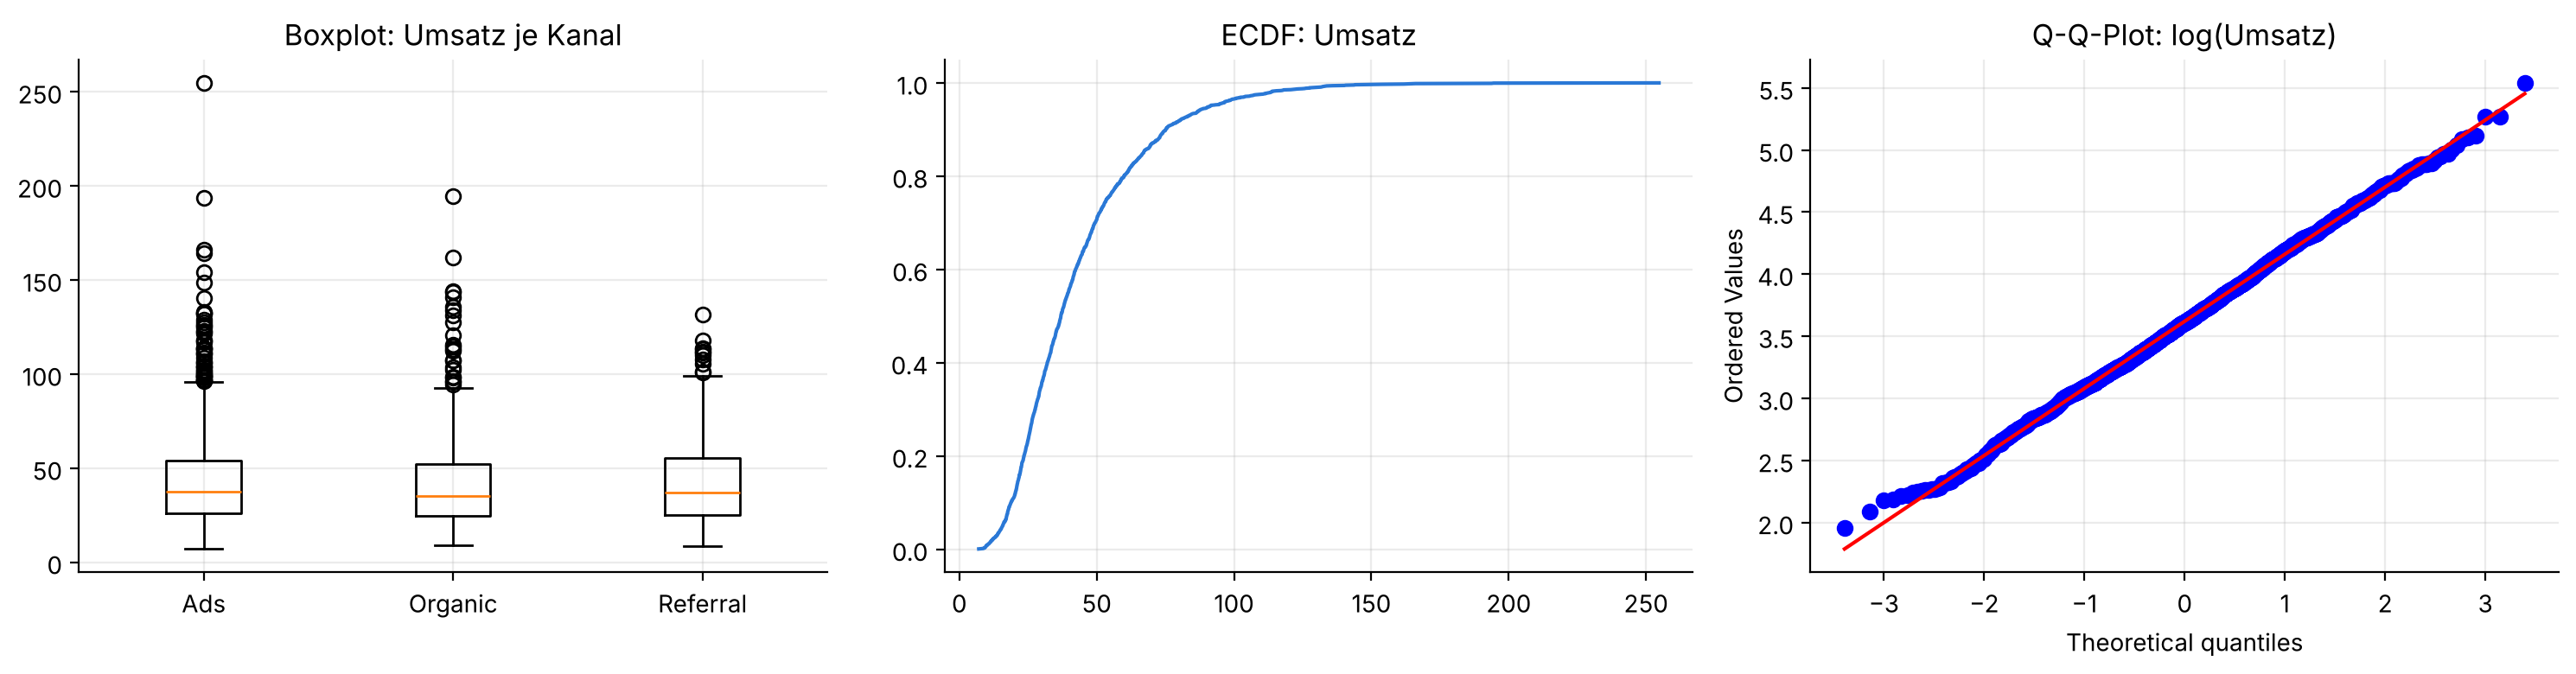

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Boxplot je Kanal
groups = [g["revenue"].to_numpy() for _, g in customers.groupby("channel")]
axes[0].boxplot(groups)
axes[0].set_xticks([1, 2, 3], sorted(customers["channel"].unique()))
axes[0].set_title("Boxplot: Umsatz je Kanal")

# ECDF
sorted_revenue = np.sort(revenue)
axes[1].plot(sorted_revenue, np.arange(1, len(sorted_revenue) + 1) / len(sorted_revenue), color=BLUE)
axes[1].set_title("ECDF: Umsatz")

# Q-Q-Plot des logarithmierten Umsatzes
stats.probplot(log_revenue, dist="norm", plot=axes[2])
axes[2].set_title("Q-Q-Plot: log(Umsatz)")
plt.tight_layout(); plt.show()

# B. Olasılık
## 7. Koşullu olasılık ve Bayes teoremi
P(A|B) = P(B|A) · P(A) / P(B)

Dolandırıcılık modeli dolandırıcılığın %99'unu yakalıyor, normal işlemlerin %2'sine yanlış alarm veriyor. Dolandırıcılık oranı %0.5. **Alarm çaldığında gerçekten dolandırıcılık olma olasılığı kaç?**

🇩🇪 **Bedingte Wahrscheinlichkeit:** Wahrscheinlichkeit von A unter der Bedingung, dass B eingetreten ist.

**Tuzak (base rate fallacy):** P(alarm|fraud) ile P(fraud|alarm) aynı şey değildir.

In [10]:
# Satz von Bayes anwenden
prior, sensitivity, false_positive_rate = 0.005, 0.99, 0.02
p_alarm = sensitivity * prior + false_positive_rate * (1 - prior)
posterior = sensitivity * prior / p_alarm
print(f"P(Betrug | Alarm) = {posterior:.1%}")

# Abhängigkeit von der Basisrate
for base_rate in [0.001, 0.005, 0.05, 0.20]:
    p = sensitivity * base_rate / (sensitivity * base_rate + false_positive_rate * (1 - base_rate))
    print(f"Basisrate {base_rate:6.1%} -> Präzision {p:.1%}")

P(Betrug | Alarm) = 19.9%
Basisrate   0.1% -> Präzision 4.7%
Basisrate   0.5% -> Präzision 19.9%
Basisrate   5.0% -> Präzision 72.3%
Basisrate  20.0% -> Präzision 92.5%


## 8. Önemli olasılık dağılımları
| Dağılım | Soru | Proje örneği |
|---|---|---|
| Bernoulli | tek deneme: oldu mu? | churn |
| Binom | n denemede kaç başarı? | dönüşüm sayısı |
| Poisson | birim zamanda kaç olay? | saatlik sipariş |
| Üstel | sonraki olaya kadar süre? | bekleme süresi |
| Normal | çok küçük etkinin toplamı | ölçüm hatası |
| Log-normal | çarpımsal etkiler | gelir |
| Uniform | her değer eşit olası | simülasyon |

🇩🇪 **Wahrscheinlichkeitsverteilung:** gibt an, wie sich Wahrscheinlichkeiten auf die möglichen Werte verteilen.

**Tuzak:** Poisson'da ortalama ≈ varyans olmalı. Varyans çok büyükse (overdispersion) negatif binom düşün.

In [11]:
# Typische Fragen mit scipy beantworten
print("P(mehr als 60 Käufe bei n=1000, p=0.05):", round(stats.binom.sf(60, 1000, 0.05), 4))
print("P(0 Bestellungen, Mittel 3 pro Stunde):  ", round(stats.poisson.pmf(0, 3), 4))
print("P(Wartezeit > 10 Min, Mittel 4 Min):     ", round(stats.expon.sf(10, scale=4), 4))
print("95%-Quantil der Standardnormalverteilung:", round(stats.norm.ppf(0.95), 3))

# 68-95-99,7-Regel
for k in [1, 2, 3]:
    print(f"Anteil innerhalb von {k} Standardabweichungen: {stats.norm.cdf(k) - stats.norm.cdf(-k):.4f}")

P(mehr als 60 Käufe bei n=1000, p=0.05): 0.0671
P(0 Bestellungen, Mittel 3 pro Stunde):   0.0498
P(Wartezeit > 10 Min, Mittel 4 Min):      0.0821
95%-Quantil der Standardnormalverteilung: 1.645
Anteil innerhalb von 1 Standardabweichungen: 0.6827
Anteil innerhalb von 2 Standardabweichungen: 0.9545
Anteil innerhalb von 3 Standardabweichungen: 0.9973


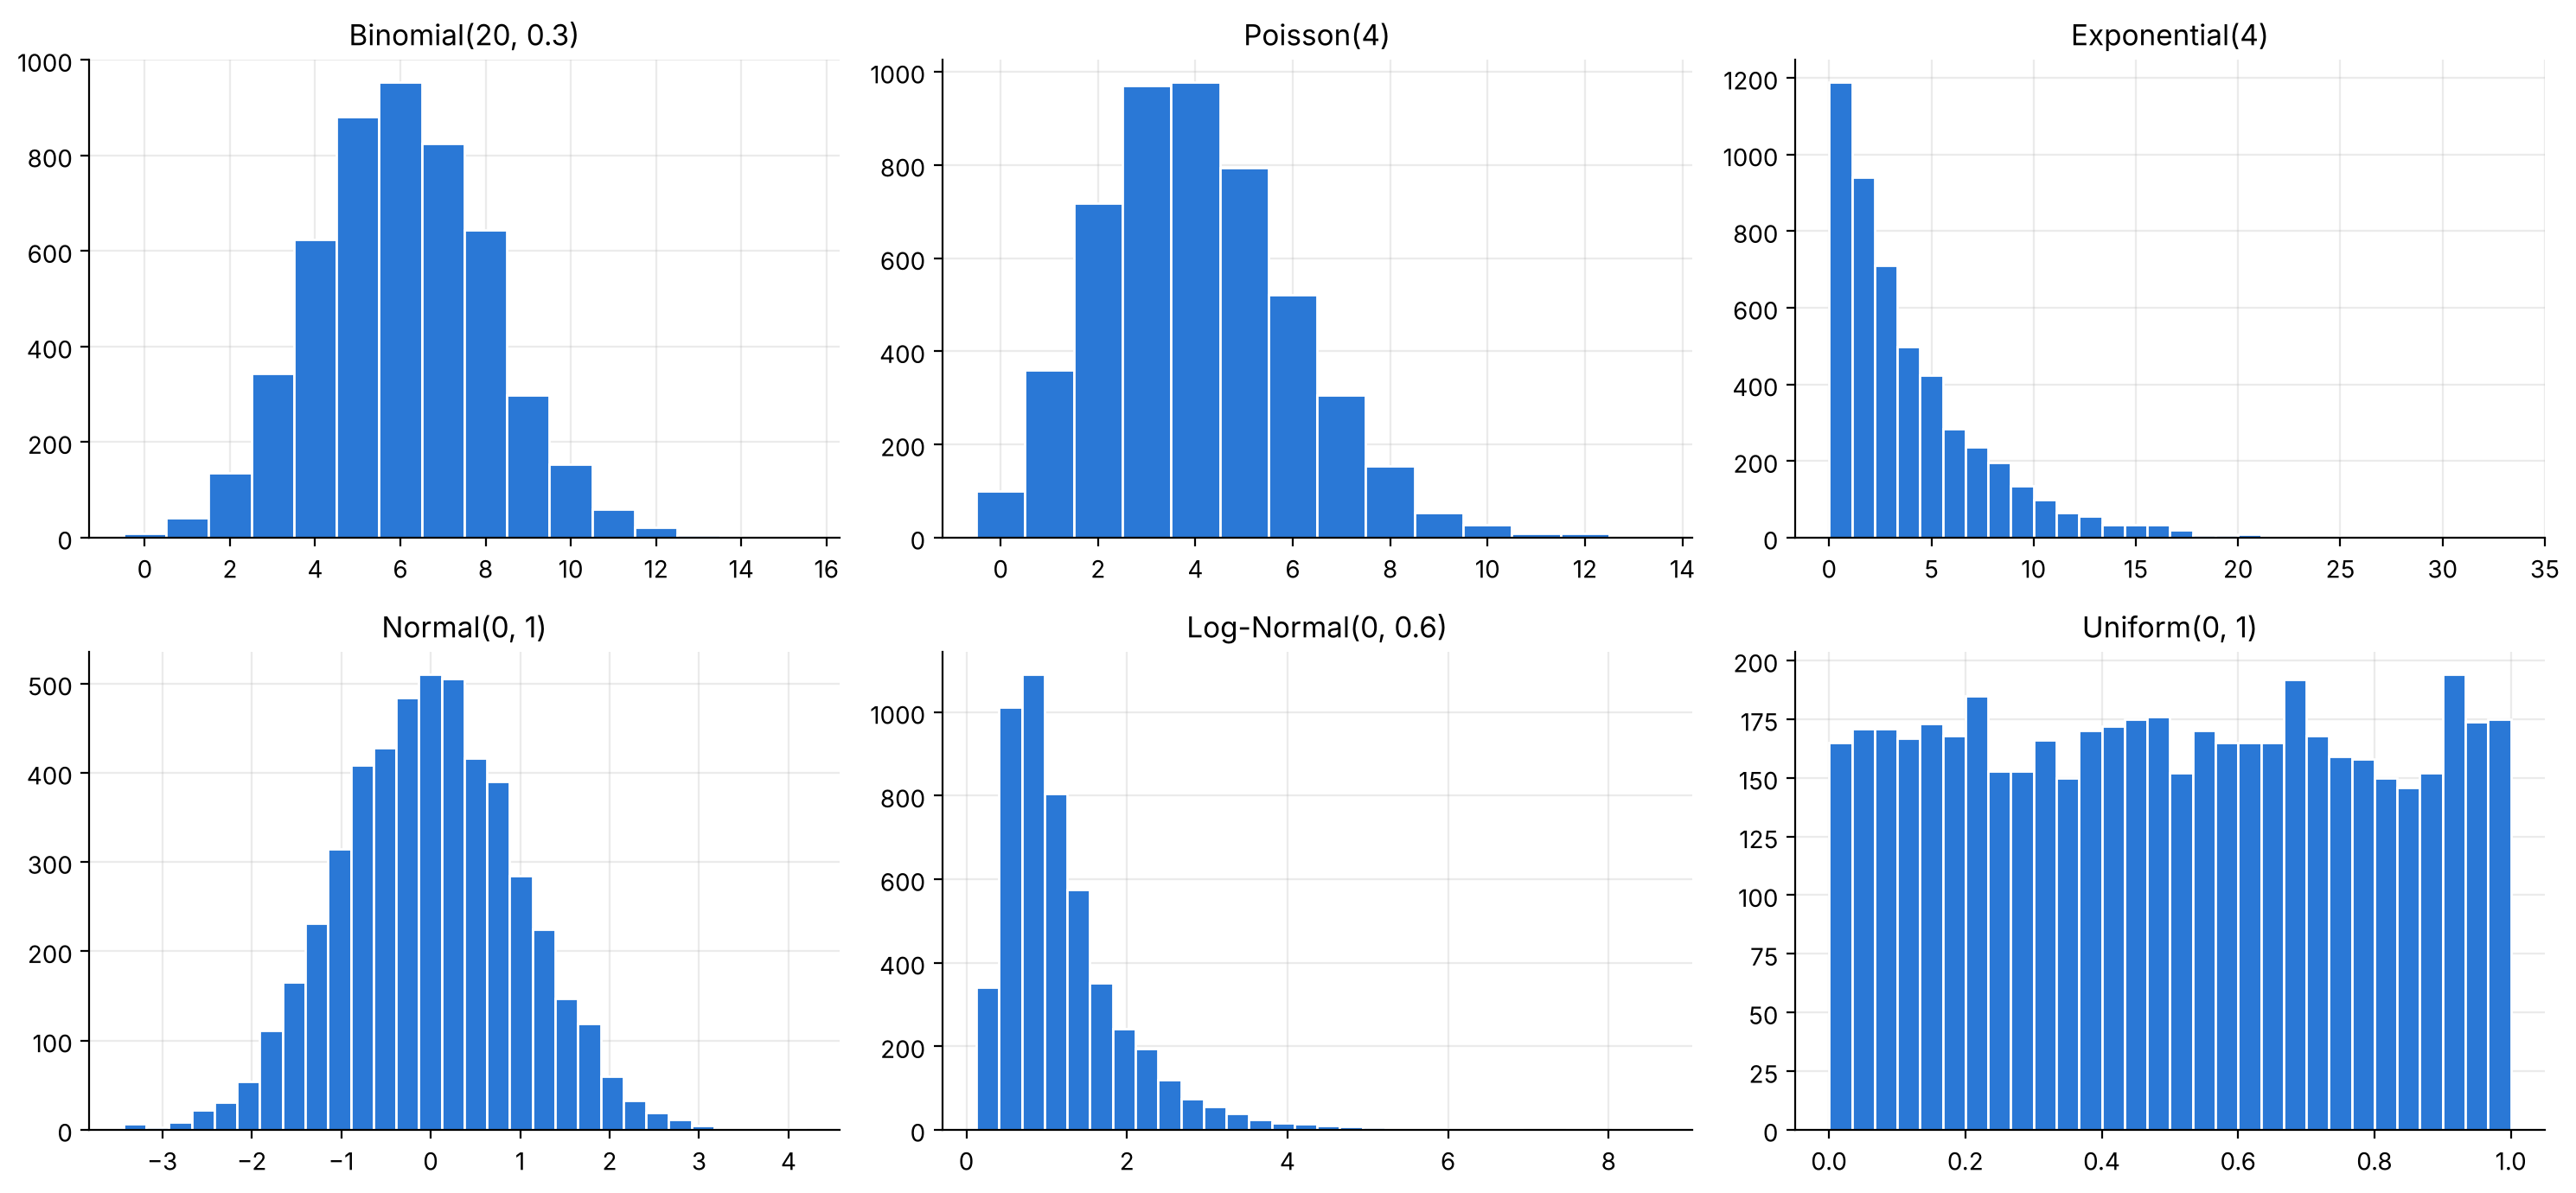

In [12]:
samples = {
    "Binomial(20, 0.3)": rng.binomial(20, 0.3, 5000), "Poisson(4)": rng.poisson(4, 5000),
    "Exponential(4)": rng.exponential(4, 5000), "Normal(0, 1)": rng.normal(0, 1, 5000),
    "Log-Normal(0, 0.6)": rng.lognormal(0, 0.6, 5000), "Uniform(0, 1)": rng.uniform(0, 1, 5000),
}
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, (title, data) in zip(axes.ravel(), samples.items()):
    # Diskrete Verteilungen: ein Balken pro ganzer Zahl
    bins = np.arange(data.min(), data.max() + 2) - 0.5 if data.dtype.kind == "i" else 30
    ax.hist(data, bins=bins, color=BLUE, edgecolor="white")
    ax.set_title(title)
plt.tight_layout(); plt.show()

## 9. Büyük sayılar yasası ve merkezi limit teoremi (CLT)
- **LLN:** örneklem büyüdükçe örneklem ortalaması gerçek ortalamaya yaklaşır.
- **CLT:** bağımsız, sonlu varyanslı veride, ana dağılım normal olmasa bile **örneklem ortalamalarının dağılımı** n büyüdükçe normale yaklaşır.

Güven aralıkları ve birçok test bu yüzden çalışır.

🇩🇪 **Zentraler Grenzwertsatz:** Die Verteilung des Stichprobenmittels nähert sich einer Normalverteilung.

**Tuzak:** CLT verinin kendisini normal yapmaz. "n=30 yeter" kuralı çok çarpık veride geçersiz olabilir.

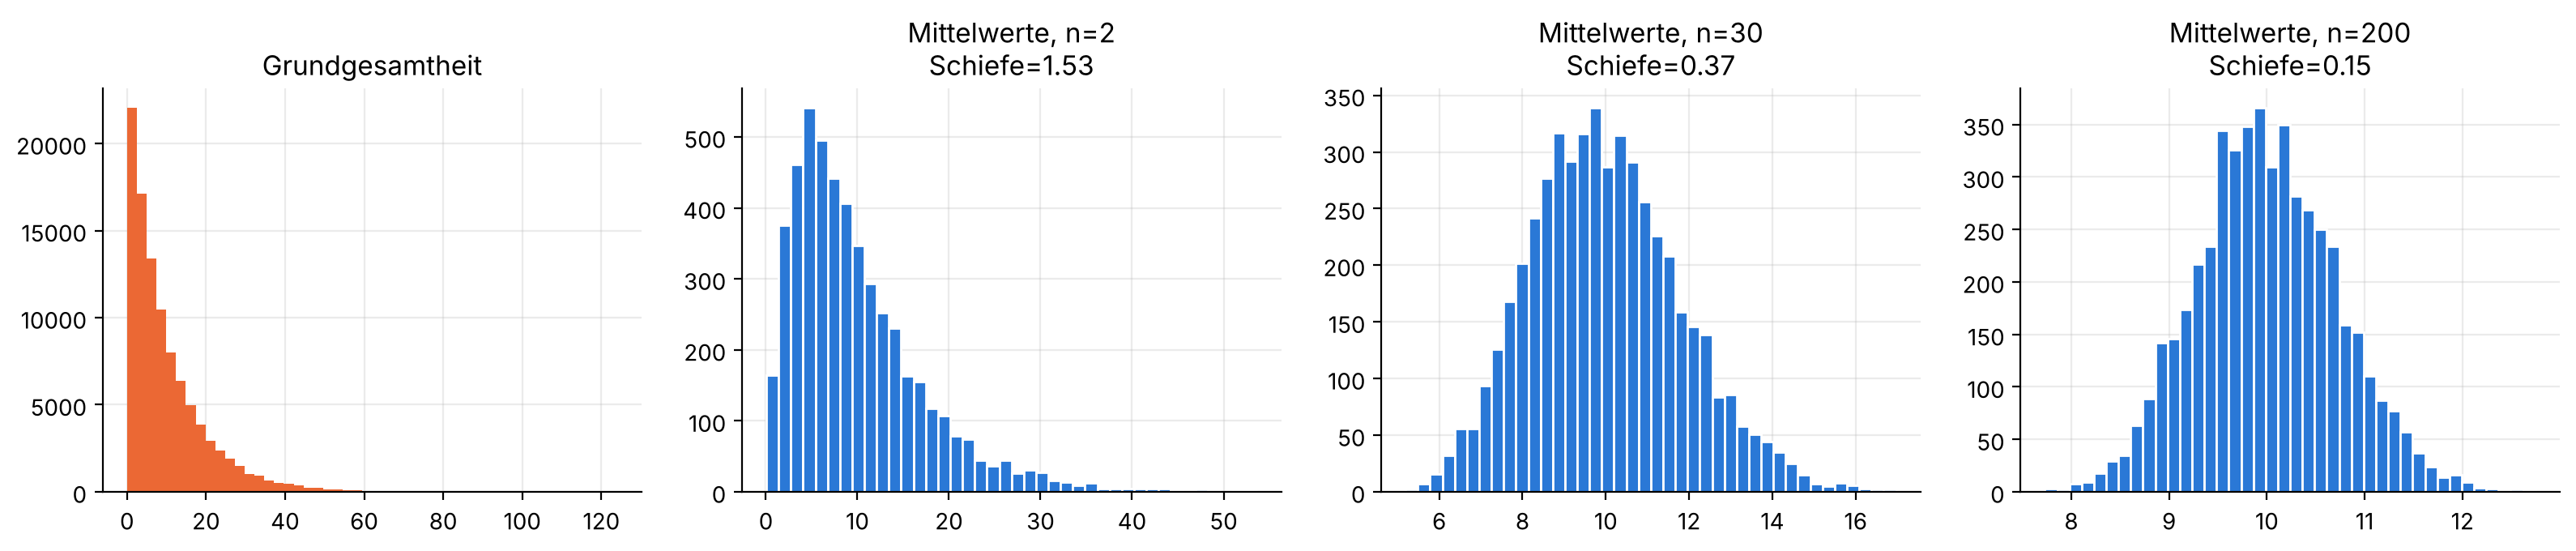

In [13]:
# Stark schiefe Grundgesamtheit
population = rng.exponential(scale=10, size=100_000)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].hist(population, bins=50, color=ORANGE); axes[0].set_title("Grundgesamtheit")

for ax, n in zip(axes[1:], [2, 30, 200]):
    means = rng.choice(population, size=(5000, n)).mean(axis=1)
    ax.hist(means, bins=40, color=BLUE, edgecolor="white")
    ax.set_title(f"Mittelwerte, n={n}\nSchiefe={stats.skew(means):.2f}")
plt.tight_layout(); plt.show()

# C. İstatistiksel Çıkarım
## 10. Örnekleme ve yanlılık
**Popülasyon** ilgilendiğin tüm küme, **örneklem** gözlediğin parçadır. Büyük ama yanlı örneklem, küçük rastgele örneklemden kötü olabilir.

| Yanlılık | Örnek |
|---|---|
| Selection bias | sadece uygulama kullanıcılarına anket |
| Survivorship bias | sadece kalan müşterileri incelemek |
| Non-response bias | yalnızca çok memnun/kızgınların cevaplaması |

🇩🇪 **Stichprobenverzerrung:** systematische Abweichung, weil die Stichprobe die Grundgesamtheit nicht abbildet.

In [14]:
# Einfache vs. geschichtete Stichprobe
simple = customers.sample(200, random_state=1)
stratified = customers.groupby("channel").sample(frac=0.10, random_state=1)

pd.DataFrame({"Gesamt": customers["channel"].value_counts(normalize=True),
              "Einfach": simple["channel"].value_counts(normalize=True),
              "Geschichtet": stratified["channel"].value_counts(normalize=True)}).round(3)

,Gesamt,Einfach,Geschichtet
channel,,,
Ads,0.505,0.44,0.505
Organic,0.288,0.35,0.290
Referral,0.206,0.21,0.205


In [15]:
# Verzerrte Stichprobe: nur Kunden mit vielen Besuchen
biased = customers[customers["visits"] >= 7]
print(f"Churn gesamt: {customers['churn'].mean():.1%} | verzerrte Stichprobe: {biased['churn'].mean():.1%}")

Churn gesamt: 32.4% | verzerrte Stichprobe: 12.0%


## 11. Standart hata ve güven aralığı
- **Std sapma:** bireysel değerlerin yayılımı.
- **Standart hata:** tahminin belirsizliği, SE = s / √n. Hatayı yarıya indirmek için yaklaşık 4 kat veri gerekir.
- **%95 güven aralığı:** yöntem çok kez tekrarlansa aralıkların yaklaşık %95'i gerçek değeri kapsar.

🇩🇪 **Konfidenzintervall:** Bereich, der nach einem Verfahren berechnet wird, das den wahren Wert in z. B. 95 % der Wiederholungen enthält.

**Tuzak:** "Gerçek değer %95 olasılıkla bu aralıkta" frekansçı yorumda yanlıştır.

In [16]:
from statsmodels.stats.proportion import proportion_confint

# Konfidenzintervall für den Mittelwert (t-Verteilung)
mean, se = revenue.mean(), stats.sem(revenue)
low, high = stats.t.interval(0.95, df=len(revenue) - 1, loc=mean, scale=se)
print(f"Mittlerer Umsatz: {mean:.2f}  95%-KI: [{low:.2f}, {high:.2f}]")

# Konfidenzintervall für einen Anteil (Wilson ist auch bei kleinen n robust)
churned, total = customers["churn"].sum(), len(customers)
low_p, high_p = proportion_confint(churned, total, method="wilson")
print(f"Churn-Rate: {churned / total:.1%}  95%-KI: [{low_p:.1%}, {high_p:.1%}]")

Mittlerer Umsatz: 43.23  95%-KI: [42.13, 44.34]
Churn-Rate: 32.4%  95%-KI: [30.4%, 34.5%]


In [17]:
# Simulation: Wie oft enthält das Intervall den wahren Mittelwert?
hits = 0
for _ in range(2000):
    sample = rng.normal(100, 15, 40)
    lo, hi = stats.t.interval(0.95, 39, loc=sample.mean(), scale=stats.sem(sample))
    hits += lo <= 100 <= hi
print(f"Abdeckung: {hits / 2000:.1%}")

Abdeckung: 95.2%


## 12. Bootstrap
Veriden **yerine koyarak** tekrar tekrar örnek çekip istatistiğin belirsizliğini tahmin eder. Medyan, oran farkı, özel metrikler gibi formülü zor durumlarda çok kullanışlıdır.

🇩🇪 **Bootstrap:** Resampling-Verfahren mit Zurücklegen zur Schätzung der Unsicherheit.

**Tuzak:** Yanlı veya çok küçük örneklemi düzeltmez. Zaman serisinde blok bootstrap gerekir.

In [18]:
# Bootstrap-Intervall für den Median
result = stats.bootstrap((revenue.to_numpy(),), np.median, n_resamples=3000,
                         method="percentile", random_state=42)
ci = result.confidence_interval
print(f"Median: {revenue.median():.2f}  95%-KI: [{ci.low:.2f}, {ci.high:.2f}]")

# Dasselbe selbst implementiert
boot_medians = np.array([np.median(rng.choice(revenue, len(revenue))) for _ in range(3000)])
print("Manuell:", np.percentile(boot_medians, [2.5, 97.5]).round(2))

Median: 36.97  95%-KI: [36.10, 38.07]


Manuell: [36.08 38.13]


# D. Hipotez Testleri
## 13. Temel mantık
1. **H0:** fark/etki yok. **H1:** var.
2. Anlamlılık düzeyi **α** (genelde 0.05) **veriye bakmadan** seçilir.
3. Test istatistiği ve **p-değeri** hesaplanır.
4. p < α ise H0 reddedilir.

**p-değeri:** H0 doğruyken, gözlenen kadar veya daha uç bir sonuç görme olasılığı.
p-değeri **H0'ın doğru olma olasılığı değildir** ve etkinin büyüklüğünü söylemez.

| | H0 doğru | H0 yanlış |
|---|---|---|
| Reddettin | **Tip I hata** (α) | Doğru karar (güç = 1−β) |
| Reddedemedin | Doğru karar | **Tip II hata** (β) |

🇩🇪 **p-Wert:** Wahrscheinlichkeit, unter H0 ein mindestens so extremes Ergebnis zu beobachten.

**Tuzak:** "Anlamlı değil" ≠ "fark yok". Güç düşük olabilir.

In [19]:
# Simulation: Unter H0 sind etwa 5 % der Tests "signifikant"
p_values = np.array([stats.ttest_ind(rng.normal(0, 1, 50), rng.normal(0, 1, 50)).pvalue
                     for _ in range(5000)])
print(f"Fehler 1. Art: {(p_values < 0.05).mean():.1%}")

# Permutationstest: p-Wert ohne Formel verstehen
group_a = rng.normal(100, 15, 80)
group_b = rng.normal(106, 15, 80)
observed = group_b.mean() - group_a.mean()
pooled = np.concatenate([group_a, group_b])
diffs = np.empty(5000)
for i in range(5000):
    shuffled = rng.permutation(pooled)
    diffs[i] = shuffled[80:].mean() - shuffled[:80].mean()
p_perm = (np.sum(np.abs(diffs) >= abs(observed)) + 1) / (len(diffs) + 1)
print(f"Beobachtete Differenz: {observed:.2f} | Permutations-p-Wert: {p_perm:.4f}")

Fehler 1. Art: 4.4%
Beobachtete Differenz: 5.13 | Permutations-p-Wert: 0.0300


## 14. Varsayımlar ve t-testleri
| Test | Soru |
|---|---|
| Tek örneklem t | ortalama hedef değerden farklı mı? |
| **Welch t** (bağımsız) | iki ayrı grubun ortalaması farklı mı? Varyans eşitliği gerektirmez, iyi varsayılan |
| Eşleştirilmiş t | aynı kişiler önce/sonra değişti mi? |

Varsayımlar: bağımsız gözlemler (en kritik), örneklem ortalamasının yaklaşık normal olması. Büyük n'de normallik testleri önemsiz sapmaları bile "anlamlı" bulur; **Q-Q plot'a da bak**.

🇩🇪 **Verbundene Stichproben:** zwei Messungen an denselben Einheiten.

In [20]:
# Voraussetzungen prüfen
print("Shapiro (Gruppe A) p:", round(stats.shapiro(group_a).pvalue, 4))
print("Levene (Varianzgleichheit) p:", round(stats.levene(group_a, group_b).pvalue, 4))

# Drei t-Test-Varianten
print("Einstichproben p:", round(stats.ttest_1samp(group_a, popmean=100).pvalue, 4))
welch = stats.ttest_ind(group_b, group_a, equal_var=False)
print(f"Welch: t={welch.statistic:.2f}, p={welch.pvalue:.4f}")

before = rng.normal(70, 10, 40)
after = before + rng.normal(2, 3, 40)
print("Gepaart p:", f"{stats.ttest_rel(after, before).pvalue:.5f}",
      "| fälschlich unabhängig p:", round(stats.ttest_ind(after, before).pvalue, 4))

Shapiro (Gruppe A) p: 0.8267
Levene (Varianzgleichheit) p: 0.2698
Einstichproben p: 0.8504
Welch: t=2.20, p=0.0293
Gepaart p: 0.00000 | fälschlich unabhängig p: 0.2228


## 15. Parametrik olmayan testler ve ANOVA
| Durum | Parametrik | Sıra temelli alternatif |
|---|---|---|
| 2 bağımsız grup | Welch t | Mann-Whitney U |
| 2 eşli ölçüm | eşli t | Wilcoxon işaretli sıra |
| 3+ grup | ANOVA | Kruskal-Wallis |

**ANOVA** "en az bir grup farklı mı?" sorusuna cevap verir. Hangisi olduğunu **Tukey HSD** gibi post-hoc test söyler.

🇩🇪 **Varianzanalyse:** vergleicht Mittelwerte von mindestens drei Gruppen.

**Tuzak:** Mann-Whitney genel olarak medyan testi değildir; dağılımlar aynı şekle sahipse öyle yorumlanabilir.

In [21]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("Mann-Whitney p:", round(stats.mannwhitneyu(group_a, group_b).pvalue, 4))
print("Wilcoxon p:    ", f"{stats.wilcoxon(after, before).pvalue:.5f}")

# ANOVA auf logarithmiertem Umsatz je Kanal
customers["log_revenue"] = np.log(customers["revenue"])
log_groups = [g["log_revenue"] for _, g in customers.groupby("channel")]
print("ANOVA p:       ", round(stats.f_oneway(*log_groups).pvalue, 4))
print("Kruskal p:     ", round(stats.kruskal(*log_groups).pvalue, 4))
print(pairwise_tukeyhsd(customers["log_revenue"], customers["channel"]))

Mann-Whitney p: 0.0291
Wilcoxon p:     0.00000
ANOVA p:        0.2362
Kruskal p:      0.3045


 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
 group1  group2  meandiff p-adj   lower  upper  reject
------------------------------------------------------
    Ads  Organic  -0.0452 0.2443 -0.1112 0.0209  False
    Ads Referral  -0.0332 0.5439 -0.1072 0.0408  False
Organic Referral    0.012  0.937 -0.0697 0.0936  False
------------------------------------------------------


## 16. Ki-kare testi ve etki büyüklüğü
**Ki-kare:** iki kategorik değişken ilişkili mi? Beklenen hücre sayıları küçükse (< 5) 2×2 tabloda **Fisher exact** kullan.

p-değeri "etki var mı", **etki büyüklüğü** "ne kadar büyük" sorusunu cevaplar.

| Ölçü | Kullanım | Kaba eşikler (küçük / orta / büyük) |
|---|---|---|
| Cohen's d | iki ortalama | 0.2 / 0.5 / 0.8 |
| Cramér's V | kategorik ilişki (df=1 için) | 0.1 / 0.3 / 0.5 |
| η² | ANOVA | 0.01 / 0.06 / 0.14 |

🇩🇪 **Effektstärke:** standardisiertes Maß für die praktische Größe eines Effekts.

In [22]:
# Zusammenhang zwischen Kanal und Kündigung
table = pd.crosstab(customers["channel"], customers["churn"])
chi2, p, dof, expected = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
print(table)
print(f"Chi²={chi2:.2f}, p={p:.2e}, Cramérs V={cramers_v:.3f}")
print("Kleinste erwartete Häufigkeit:", expected.min().round(1))

churn       0    1
channel           
Ads       633  378
Organic   411  166
Referral  308  104
Chi²=24.60, p=4.56e-06, Cramérs V=0.111
Kleinste erwartete Häufigkeit: 133.5


In [23]:
def cohens_d(a, b):
    """Standardisierte Mittelwertdifferenz mit gepoolter Standardabweichung."""
    na, nb = len(a), len(b)
    pooled_sd = np.sqrt(((na - 1) * np.var(a, ddof=1) + (nb - 1) * np.var(b, ddof=1)) / (na + nb - 2))
    return (np.mean(b) - np.mean(a)) / pooled_sd

print("Cohens d:", round(cohens_d(group_a, group_b), 3))

# Große Stichprobe: winziger Effekt wird signifikant
big_a, big_b = rng.normal(100, 15, 500_000), rng.normal(100.2, 15, 500_000)
print(f"p={stats.ttest_ind(big_a, big_b).pvalue:.2e}, d={cohens_d(big_a, big_b):.4f}")

Cohens d: 0.348


p=2.45e-09, d=0.0119


## 17. Güç analizi ve örneklem büyüklüğü
Deneyden **önce** dört büyüklükten üçünü belirle, dördüncüsünü hesapla: α, güç (genelde 0.80), minimum tespit edilebilir etki (MDE), n.

🇩🇪 **Teststärke (Power):** Wahrscheinlichkeit, einen tatsächlich vorhandenen Effekt zu erkennen.

**Pratik:** MDE'yi yarıya indirmek yaklaşık 4 kat örneklem ister. MDE'yi iş değeri belirler.

In [24]:
from statsmodels.stats.power import TTestIndPower, NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# Stichprobe pro Gruppe für verschiedene Effektstärken
for d in [0.2, 0.5, 0.8]:
    n = TTestIndPower().solve_power(effect_size=d, alpha=0.05, power=0.80)
    print(f"d={d}: {np.ceil(n):.0f} pro Gruppe")

# Conversion von 10 % auf 12 % erhöhen
effect = proportion_effectsize(0.12, 0.10)
n_required = int(np.ceil(NormalIndPower().solve_power(effect, alpha=0.05, power=0.80)))
print("Benötigt pro Variante:", n_required)

d=0.2: 394 pro Gruppe
d=0.5: 64 pro Gruppe
d=0.8: 26 pro Gruppe
Benötigt pro Variante: 3835


## 18. A/B testi: uçtan uca
1. Hipotez ve **birincil metrik** · 2. Guardrail metrikleri · 3. MDE ve örneklem · 4. Rastgele atama
5. **SRM kontrolü** (gruplar planlanan oranda mı?) · 6. Süreyi tamamla (tam haftalar) · 7. Test, güven aralığı, karar

🇩🇪 **Sample Ratio Mismatch:** Die tatsächliche Gruppenaufteilung weicht auffällig von der geplanten ab.

**Tuzaklar:** erken bakıp durmak (peeking), sonradan metrik değiştirmek, kullanıcı yerine oturum bazında analiz, yenilik etkisi.

In [25]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

# Experiment simulieren (wahre Raten: 10 % und 12 %)
# Zufällige Zuteilung: jeder Nutzer landet mit 50 % in A
n_a = rng.binomial(2 * n_required, 0.5)
n_b = 2 * n_required - n_a
conv_a, conv_b = rng.binomial(n_a, 0.10), rng.binomial(n_b, 0.12)

# Schritt 1: Sample Ratio Mismatch prüfen
print("SRM p:", round(stats.chisquare([n_a, n_b]).pvalue, 4))

# Schritt 2: Test und Intervall für die Differenz
z, p_ab = proportions_ztest([conv_b, conv_a], [n_b, n_a])
low, high = confint_proportions_2indep(conv_b, n_b, conv_a, n_a, compare="diff")
rate_a, rate_b = conv_a / n_a, conv_b / n_b
print(f"A: {rate_a:.2%} | B: {rate_b:.2%} | relativer Uplift: {rate_b / rate_a - 1:+.1%}")
print(f"p={p_ab:.4f} | 95%-KI der Differenz: [{low:.2%}, {high:.2%}]")

SRM p: 0.2831
A: 9.95% | B: 11.62% | relativer Uplift: +16.7%
p=0.0188 | 95%-KI der Differenz: [0.28%, 3.05%]


In [26]:
# Peeking: wiederholtes Testen erhöht die Fehlerrate (A/A-Test, kein echter Effekt)
false_alarms_peek, false_alarms_end = 0, 0
for _ in range(1000):
    a = rng.binomial(1, 0.10, 5000); b = rng.binomial(1, 0.10, 5000)
    checks = np.arange(500, 5001, 500)
    p_list = [proportions_ztest([a[:k].sum(), b[:k].sum()], [k, k])[1] for k in checks]
    false_alarms_peek += min(p_list) < 0.05
    false_alarms_end += p_list[-1] < 0.05
print(f"Nur am Ende testen: {false_alarms_end / 1000:.1%} | 10-mal nachsehen: {false_alarms_peek / 1000:.1%}")

Nur am Ende testen: 5.8% | 10-mal nachsehen: 19.7%


## 19. Çoklu test problemi
20 bağımsız testte, hepsinde H0 doğruyken en az bir yanlış pozitif olasılığı: 1 − 0.95²⁰ ≈ %64.

- **Bonferroni / Holm:** en az bir yanlış pozitif riskini (FWER) kontrol eder. Holm daha güçlüdür.
- **Benjamini-Hochberg:** yanlış keşif oranını (FDR) kontrol eder; çok sayıda metrik/özellik taramada yaygın.

🇩🇪 **Multiples Testproblem:** Mit der Zahl der Tests steigt die Wahrscheinlichkeit zufälliger Treffer.

In [27]:
from statsmodels.stats.multitest import multipletests

# 90 Tests ohne Effekt und 10 Tests mit echtem Effekt
p_null = [stats.ttest_ind(rng.normal(0, 1, 60), rng.normal(0, 1, 60)).pvalue for _ in range(90)]
p_real = [stats.ttest_ind(rng.normal(0, 1, 60), rng.normal(0.8, 1, 60)).pvalue for _ in range(10)]
all_p = np.array(p_null + p_real)

rows = [("Keine Korrektur", all_p < 0.05)]
for method in ["bonferroni", "holm", "fdr_bh"]:
    rows.append((method, multipletests(all_p, alpha=0.05, method=method)[0]))
pd.DataFrame([{"Methode": m, "Falsch positiv": r[:90].sum(), "Richtig erkannt": r[90:].sum()}
              for m, r in rows])

,Methode,Falsch positiv,Richtig erkannt
0,Keine Korrektur,6,9
1,bonferroni,0,7
2,holm,1,7
3,fdr_bh,1,9


# E. İlişki ve Modelleme
## 20. Korelasyon
| Katsayı | Ölçtüğü |
|---|---|
| Pearson | doğrusal ilişki, aykırıya hassas |
| Spearman | monoton ilişki (sıralar) |
| Kendall | sıra uyumu, küçük örneklemde kullanışlı |

🇩🇪 **Korrelation:** Stärke und Richtung eines Zusammenhangs, kein Beweis für Kausalität.

**Tuzak:** r = 0 "ilişki yok" demek değildir. **Her zaman grafiğe bak.**

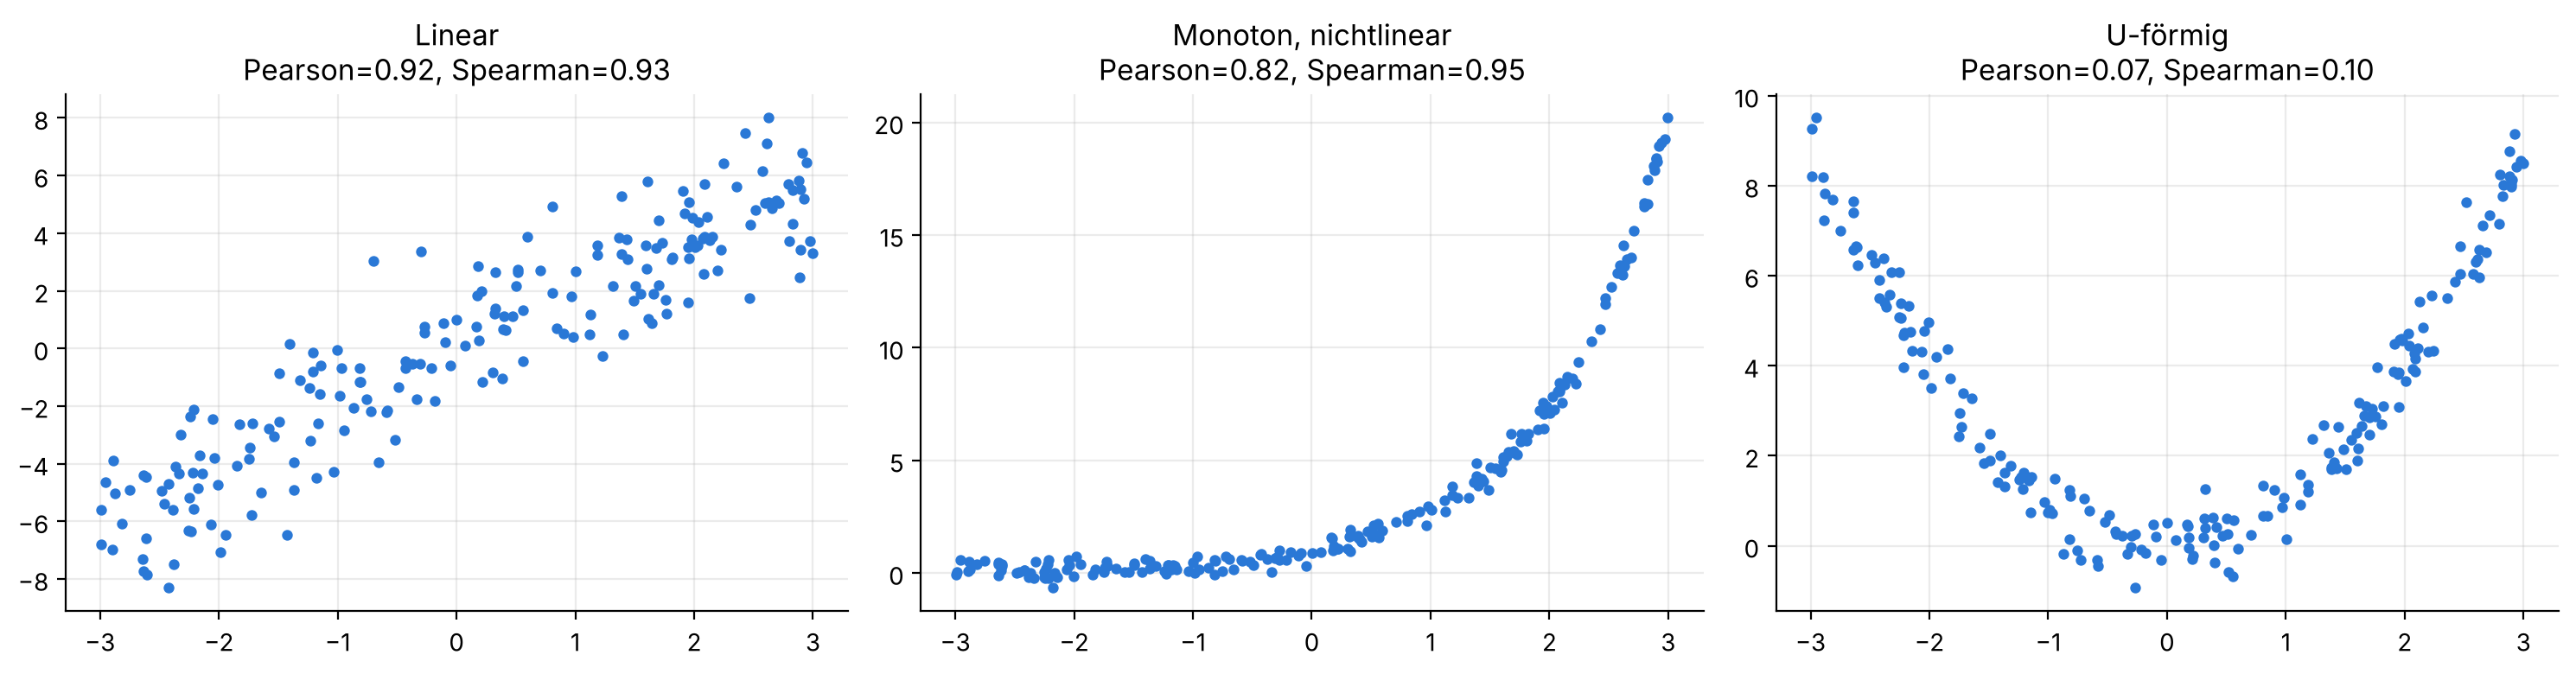

In [28]:
x = rng.uniform(-3, 3, 200)
cases = {"Linear": 2 * x + rng.normal(0, 1.5, 200),
         "Monoton, nichtlinear": np.exp(x) + rng.normal(0, 0.3, 200),
         "U-förmig": x**2 + rng.normal(0, 0.5, 200)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, y) in zip(axes, cases.items()):
    ax.scatter(x, y, s=12, color=BLUE)
    ax.set_title(f"{title}\nPearson={stats.pearsonr(x, y)[0]:.2f}, Spearman={stats.spearmanr(x, y)[0]:.2f}")
plt.tight_layout(); plt.show()

## 21. Confounding ve Simpson paradoksu
Gizli bir üçüncü değişken ilişkiyi yaratabilir veya **yönünü tersine çevirebilir**. Aşağıda B tedavisi toplamda daha iyi görünür, ama her iki alt grupta A daha iyidir; çünkü A çoğunlukla zor vakalara uygulanmıştır.

🇩🇪 **Störvariable (Confounder):** beeinflusst sowohl die Ursache als auch die Wirkung.

In [29]:
simpson = pd.DataFrame({
    "treatment": ["A", "A", "B", "B"], "severity": ["leicht", "schwer", "leicht", "schwer"],
    "success": [81, 192, 234, 55], "total": [87, 263, 270, 80],
})
simpson["rate"] = simpson["success"] / simpson["total"]
display(simpson.round(3))

overall = simpson.groupby("treatment")[["success", "total"]].sum()
overall.assign(rate=overall["success"] / overall["total"]).round(3)

,treatment,severity,success,total,rate
0,A,leicht,81,87,0.931
1,A,schwer,192,263,0.730
2,B,leicht,234,270,0.867
3,B,schwer,55,80,0.688


,success,total,rate
treatment,,,
A,273,350,0.780
B,289,350,0.826


## 22. Lineer regresyon
y = β₀ + β₁x₁ + … + ε

- **Katsayı:** diğer değişkenler sabitken x bir birim artınca y'nin beklenen değişimi.
- **R² / düzeltilmiş R²:** açıklanan varyans oranı.
- Varsayımlar: doğrusallık, bağımsız hatalar, sabit hata varyansı, (küçük n'de) normal hatalar, güçlü multicollinearity olmaması.
- Hedef log ise katsayı yaklaşık **yüzde etki**dir: 100·(e^β − 1).

🇩🇪 **Residuum:** Differenz zwischen beobachtetem und vorhergesagtem Wert.

In [30]:
# Regression auf logarithmiertem Umsatz (wahre Koeffizienten: visits 0.08, age 0.005)
ols = smf.ols("log_revenue ~ visits + age + C(channel)", data=customers).fit()
print(ols.summary())
print(f"Ein zusätzlicher Besuch: {100 * (np.exp(ols.params['visits']) - 1):+.1f} % Umsatz")

                            OLS Regression Results                            
Dep. Variable:            log_revenue   R-squared:                       0.158
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     93.75
Date:                Fri, 27 Nov 2026   Prob (F-statistic):           3.85e-73
Time:                        02:40:08   Log-Likelihood:                -1432.6
No. Observations:                2000   AIC:                             2875.
Df Residuals:                    1995   BIC:                             2903.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  2

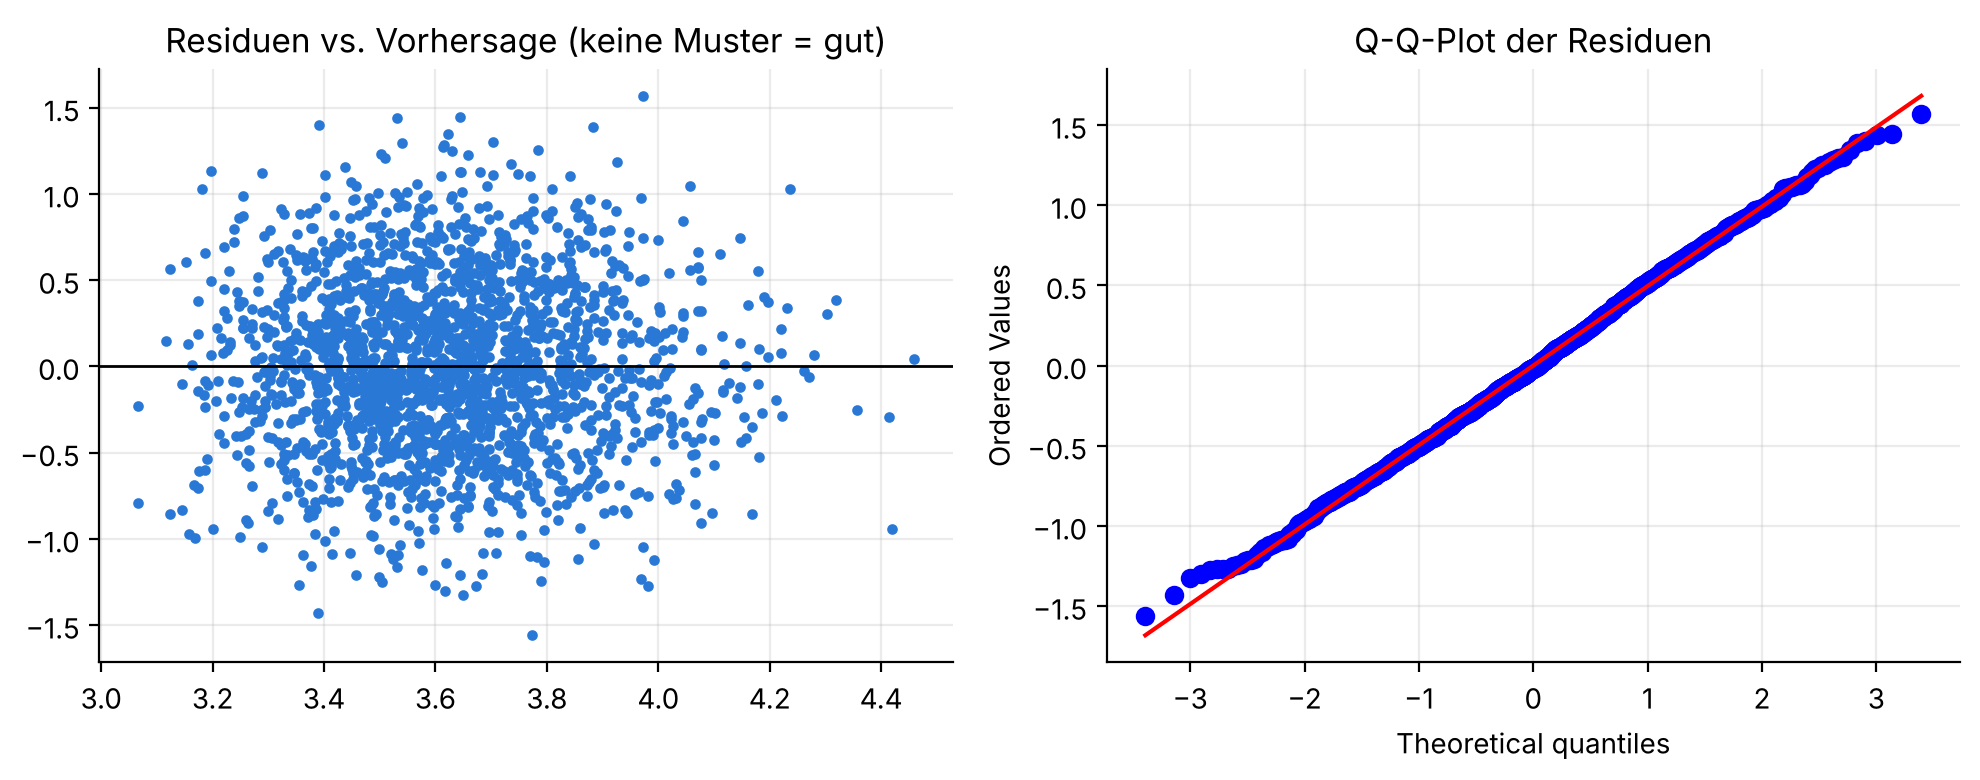

Breusch-Pagan p: 0.9897
VIF visits: 59.2
VIF age: 1.0
VIF visits_copy: 59.2


In [31]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

fig, axes = plt.subplots(1, 2)
axes[0].scatter(ols.fittedvalues, ols.resid, s=8, color=BLUE)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_title("Residuen vs. Vorhersage (keine Muster = gut)")
stats.probplot(ols.resid, plot=axes[1]); axes[1].set_title("Q-Q-Plot der Residuen")
plt.tight_layout(); plt.show()

# Heteroskedastizität und Multikollinearität prüfen
print("Breusch-Pagan p:", round(het_breuschpagan(ols.resid, ols.model.exog)[1], 4))
X_vif = sm.add_constant(customers[["visits", "age"]]).assign(
    visits_copy=lambda d: d["visits"] + rng.normal(0, 0.3, len(d)))
for i, col in enumerate(X_vif.columns[1:], start=1):
    print(f"VIF {col}: {variance_inflation_factor(X_vif.to_numpy(float), i):.1f}")

**VIF yorumu:** 5–10 üstü uyarı işaretidir (kural kesin değil). Neredeyse aynı iki sütun (`visits`, `visits_copy`) katsayıları kararsızlaştırır. Heteroskedastisite varsa `fit(cov_type="HC3")` ile sağlam standart hata kullan.

## 23. Lojistik regresyon
İkili hedef için. Model **log-odds**'u doğrusal tahmin eder. e^β = **odds ratio**: 1'den büyükse olasılığı artırır, küçükse azaltır.

🇩🇪 **Chancenverhältnis (Odds Ratio):** Faktor, um den sich die Chancen bei Anstieg um eine Einheit ändern.

**Tuzak:** Odds ratio, olasılık oranı (relative risk) değildir.

In [32]:
logit_model = smf.logit("churn ~ visits + age + C(channel)", data=customers).fit(disp=False)
odds = pd.DataFrame({"odds_ratio": np.exp(logit_model.params),
                     "ci_low": np.exp(logit_model.conf_int()[0]),
                     "ci_high": np.exp(logit_model.conf_int()[1]),
                     "p_value": logit_model.pvalues})
odds.round(4)

,odds_ratio,ci_low,ci_high,p_value
Intercept,3.1166,2.0931,4.6407,0.0000
C(channel)[T.Organic],0.6054,0.4786,0.7658,0.0000
C(channel)[T.Referral],0.5052,0.3844,0.6638,0.0000
visits,0.6845,0.6497,0.7212,0.0000
age,1.0037,0.9971,1.0104,0.2745


# F. Model Değerlendirme
## 24. Bias-variance ve cross-validation
- **Underfitting (yüksek bias):** train ve validation hatası yüksek.
- **Overfitting (yüksek variance):** train hatası düşük, validation hatası yüksek.
- **k-fold CV:** veriyi k parçaya bölüp ortalama ve yayılımı raporla. Sınıflandırmada stratified, zaman serisinde `TimeSeriesSplit`, aynı müşteriden çok satır varsa `GroupKFold`.

🇩🇪 **Überanpassung:** Das Modell lernt das Rauschen der Trainingsdaten mit.

In [33]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression

x_cv = rng.uniform(-3, 3, 80).reshape(-1, 1)
y_cv = np.sin(x_cv).ravel() + rng.normal(0, 0.3, 80)
rows = []
for degree in [1, 3, 15]:
    model = make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())
    scores = cross_validate(model, x_cv, y_cv, cv=KFold(5, shuffle=True, random_state=0),
                            scoring="neg_root_mean_squared_error", return_train_score=True)
    rows.append({"Grad": degree, "Train-RMSE": -scores["train_score"].mean(),
                 "Validierungs-RMSE": -scores["test_score"].mean()})
pd.DataFrame(rows).round(3)

,Grad,Train-RMSE,Validierungs-RMSE
0,1,0.480,0.484
1,3,0.266,0.275
2,15,0.251,0.509


## 25. Model metrikleri
| Metrik | Soru |
|---|---|
| Precision | pozitif dediklerimin kaçı doğru? |
| Recall | gerçek pozitiflerin kaçını yakaladım? |
| F1 | ikisinin harmonik ortalaması |
| ROC-AUC | rastgele bir pozitifi negatiften yüksek sıralama olasılığı |
| PR-AUC | nadir pozitif sınıfta daha bilgilendirici |
| Brier | olasılık tahminlerinin doğruluğu |
| MAE / RMSE / MAPE | regresyon; RMSE büyük hatayı daha çok cezalandırır, MAPE sıfıra yakın değerlerde bozulur |

🇩🇪 **Trefferquote (Recall):** Anteil der tatsächlich positiven Fälle, die erkannt wurden.

**Tuzak:** %99 negatif veride hep "negatif" diyen model %99 accuracy alır. Eşik 0.5 olmak zorunda değil; hata maliyetine göre seç. Eşiği **test setinde değil**, validation setinde seç.

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             mean_absolute_error, mean_squared_error,
                             mean_absolute_percentage_error)

features = pd.get_dummies(customers[["visits", "age", "channel"]], drop_first=True)
X_train, X_temp, y_train, y_temp = train_test_split(
    features, customers["churn"], test_size=0.4, stratify=customers["churn"], random_state=42)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)

classifier = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_train, y_train)
val_proba = classifier.predict_proba(X_val)[:, 1]

# Schwellenwert anhand der Kosten wählen: verpasster Churn 5-mal teurer als Fehlalarm
thresholds = np.linspace(0.05, 0.95, 91)
costs = [5 * np.sum((y_val == 1) & (val_proba < t)) + np.sum((y_val == 0) & (val_proba >= t))
         for t in thresholds]
best_threshold = thresholds[int(np.argmin(costs))]
print(f"Bester Schwellenwert (Validierung): {best_threshold:.2f}")

Bester Schwellenwert (Validierung): 0.13


In [35]:
# Finale Bewertung auf dem Testdatensatz
test_proba = classifier.predict_proba(X_test)[:, 1]
rows = []
for t in [0.5, best_threshold]:
    pred = (test_proba >= t).astype(int)
    print(f"Schwellenwert {t:.2f}:\n{confusion_matrix(y_test, pred)}")
    rows.append({"Schwelle": round(t, 2), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
print("Basisrate:", round(y_test.mean(), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
print("PR-AUC: ", round(average_precision_score(y_test, test_proba), 3))
print("Brier:  ", round(brier_score_loss(y_test, test_proba), 3))
pd.DataFrame(rows).round(3)

Schwellenwert 0.50:
[[235  36]
 [ 92  37]]
Schwellenwert 0.13:
[[ 40 231]
 [  6 123]]
Basisrate: 0.322
ROC-AUC: 0.687
PR-AUC:  0.459
Brier:   0.202


,Schwelle,Precision,Recall,F1
0,0.50,0.507,0.287,0.366
1,0.13,0.347,0.953,0.509


In [36]:
# Regressionsmetriken
y_true = np.array([100, 120, 90, 110, 10])
y_pred = np.array([102, 115, 95, 108, 40])
print("MAE: ", mean_absolute_error(y_true, y_pred))
print("RMSE:", round(np.sqrt(mean_squared_error(y_true, y_pred)), 2))
print("MAPE:", f"{mean_absolute_percentage_error(y_true, y_pred):.1%}")

MAE:  8.8
RMSE: 13.84
MAPE: 62.7%


## 26. Data leakage
Eğitimde, tahmin anında bilinmeyecek bilginin kullanılmasıdır. Skor harika görünür, canlıda çöker.

- Scaler / imputer / feature selection **bölmeden önce** fit edildi → `Pipeline` kullan.
- Hedeften türeyen sütun (ör. `cancel_date`).
- Zaman serisinde geleceği kullanmak.

🇩🇪 **Datenleck:** Informationen, die zum Vorhersagezeitpunkt nicht verfügbar wären, gelangen ins Training.

Demo: **tamamen rastgele** veride özellik seçimini yanlış yerde yapmak sahte başarı üretir.

In [37]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score

noise_X = rng.normal(size=(100, 5000))
noise_y = rng.integers(0, 2, 100)

# Falsch: Merkmalsauswahl auf allen Daten
leaky_X = SelectKBest(f_classif, k=20).fit_transform(noise_X, noise_y)
leaky = cross_val_score(LogisticRegression(), leaky_X, noise_y, cv=5).mean()

# Richtig: Auswahl innerhalb der Pipeline, also je Fold neu
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression())
clean = cross_val_score(pipe, noise_X, noise_y, cv=5).mean()
print(f"Mit Leakage: {leaky:.2f} | Korrekt: {clean:.2f} (Zufall = 0.50)")

Mit Leakage: 0.92 | Korrekt: 0.56 (Zufall = 0.50)


# G. İleri Konular
## 27. Bayesçi A/B testi
Önsel inanç + veri → sonsal dağılım. Dönüşüm için Beta(1,1) önsel kullanırsak sonsal Beta(1+başarı, 1+başarısızlık) olur. İş tarafına anlatması kolay: **"B'nin A'dan iyi olma olasılığı"**.

🇩🇪 **A-posteriori-Verteilung:** aktualisierte Verteilung eines Parameters nach Beobachtung der Daten.

**Not:** Sonuç önsele ve model varsayımlarına bağlıdır.

P(B > A) = 99.1%
Erwarteter Verlust bei Wahl von B: 0.00212%


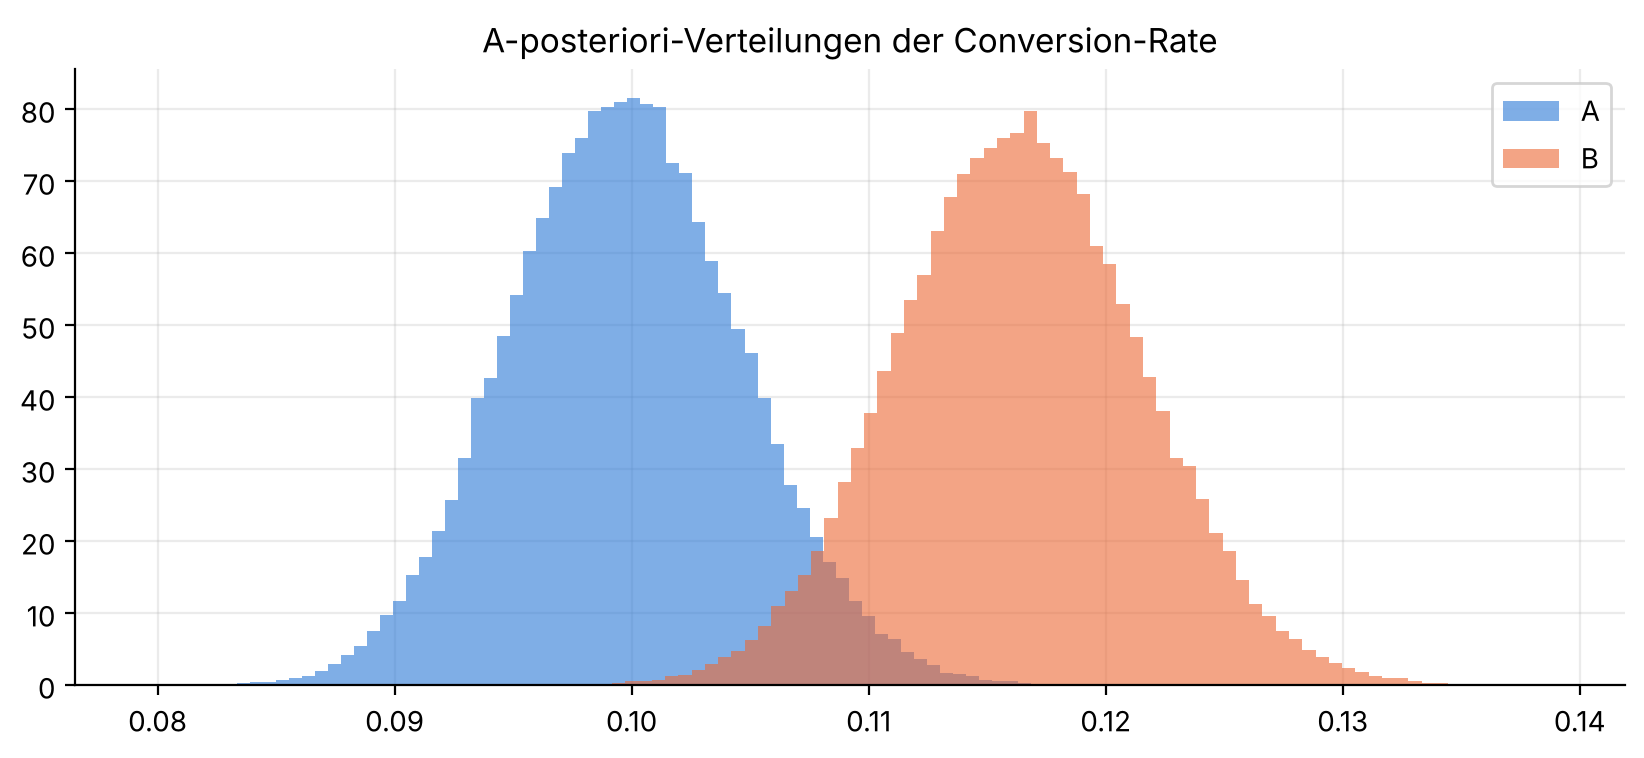

In [38]:
post_a = rng.beta(1 + conv_a, 1 + n_a - conv_a, 100_000)
post_b = rng.beta(1 + conv_b, 1 + n_b - conv_b, 100_000)
print(f"P(B > A) = {(post_b > post_a).mean():.1%}")
print("Erwarteter Verlust bei Wahl von B:", f"{np.maximum(post_a - post_b, 0).mean():.5%}")

fig, ax = plt.subplots()
ax.hist(post_a, bins=80, alpha=0.6, density=True, color=BLUE, label="A")
ax.hist(post_b, bins=80, alpha=0.6, density=True, color=ORANGE, label="B")
ax.set_title("A-posteriori-Verteilungen der Conversion-Rate"); ax.legend(); plt.show()

## 28. Zaman serisi temelleri
- Bileşenler: **trend, mevsimsellik, artık**.
- **Durağanlık:** istatistiksel özellikler zamanla değişmez. ADF testinde H0 "birim kök var"dır; küçük p durağanlık lehine kanıttır.
- **Otokorelasyon:** seri geçmişiyle ilişkili.
- Modeli her zaman **naive / seasonal naive** tahminle karşılaştır; veriyi zamana göre böl.

🇩🇪 **Stationarität:** Mittelwert und Varianzstruktur ändern sich über die Zeit nicht.

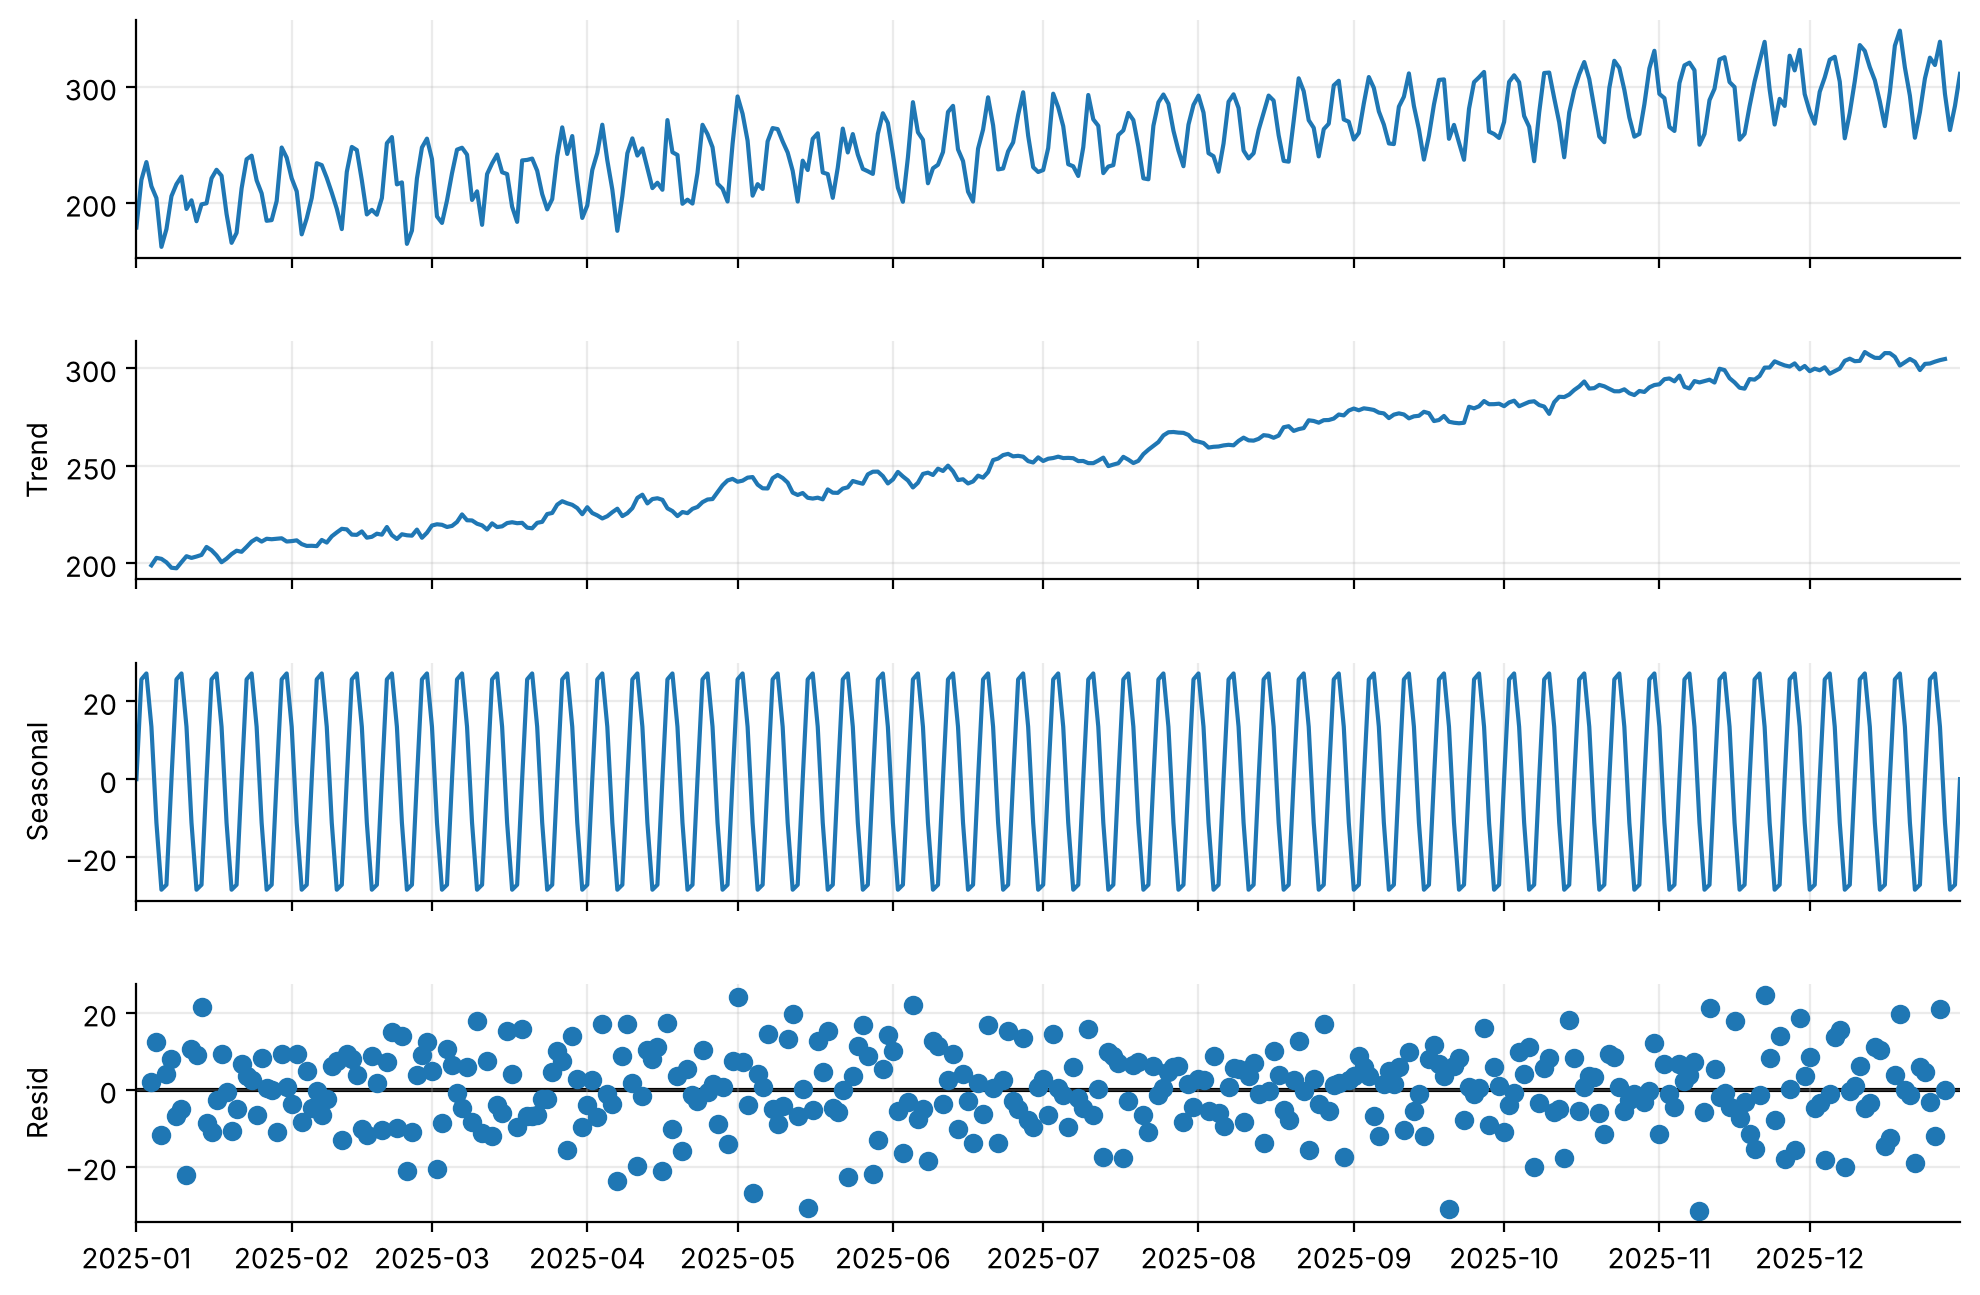

ADF p (Original):     0.8951
ADF p (differenziert): 8.40e-17


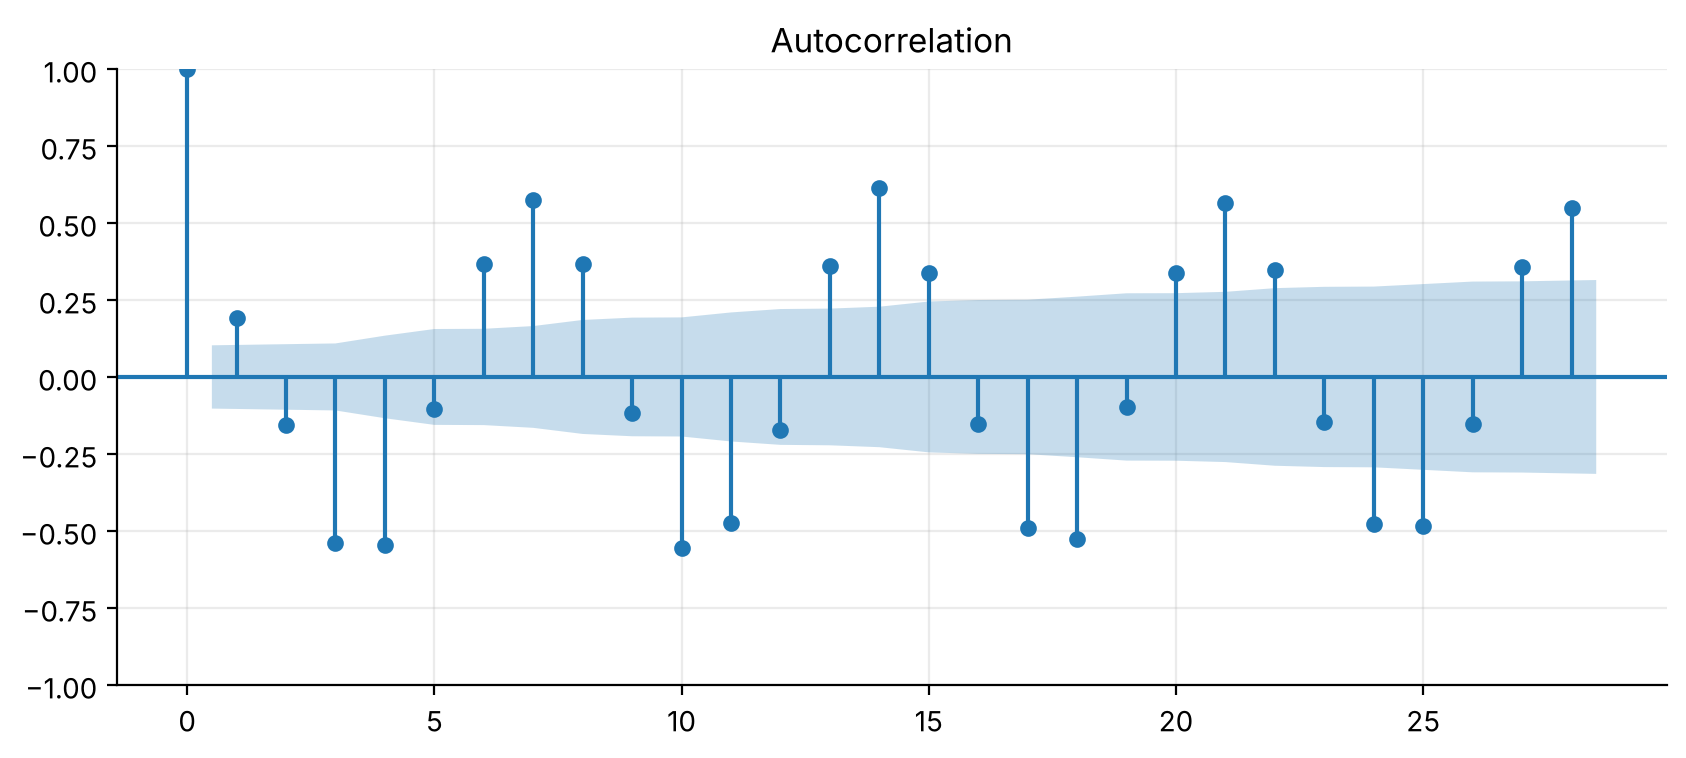

In [39]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf

# Tägliche Verkäufe: Trend + Wochenmuster + Rauschen
dates = pd.date_range("2025-01-01", periods=365, freq="D")
sales = pd.Series(200 + 0.3 * np.arange(365) + 30 * np.sin(2 * np.pi * np.arange(365) / 7)
                  + rng.normal(0, 10, 365), index=dates)
fig = seasonal_decompose(sales, period=7).plot(); fig.set_size_inches(10, 7); plt.show()

print("ADF p (Original):    ", round(adfuller(sales)[1], 4))
print("ADF p (differenziert):", f"{adfuller(sales.diff().dropna())[1]:.2e}")
plot_acf(sales.diff().dropna(), lags=28); plt.show()

In [40]:
# Vergleich mit einfachen Basismodellen auf den letzten 28 Tagen
train, test = sales[:-28], sales[-28:]
naive = np.repeat(train.iloc[-1], 28)
seasonal_naive = np.tile(train.iloc[-7:], 4)
print("MAE naiv:         ", round(mean_absolute_error(test, naive), 2))
print("MAE saisonal naiv:", round(mean_absolute_error(test, seasonal_naive), 2))

MAE naiv:          22.62
MAE saisonal naiv: 11.19


## 29. Nedensellik
"Birlikte değişiyor" ≠ "neden oluyor". Altın standart **rastgele kontrollü deney**. Deney yoksa:

| Yöntem | Fikir | Kritik varsayım |
|---|---|---|
| Regresyonla kontrol | confounder'ları modele ekle | hepsi ölçülmüş |
| Propensity score | benzer kişileri eşleştir | gizli confounder yok, örtüşme |
| Difference-in-Differences | değişim farkı | paralel trendler |
| Regression discontinuity | eşik çevresini karşılaştır | eşikte manipülasyon yok |
| Instrumental variable | dışsal değişken | araç yalnızca neden üzerinden etkiler |

🇩🇪 **Kausalität:** Eine Änderung der Ursache bewirkt eine Änderung der Wirkung.

In [41]:
# Difference-in-Differences: wahrer Effekt der Maßnahme = 8
n = 500
did = pd.DataFrame({"treated": rng.integers(0, 2, n * 2), "post": np.repeat([0, 1], n)})
did["outcome"] = (50 + 10 * did["treated"] + 5 * did["post"]
                  + 8 * did["treated"] * did["post"] + rng.normal(0, 6, n * 2))
did_model = smf.ols("outcome ~ treated * post", data=did).fit()
print(f"Geschätzter Effekt: {did_model.params['treated:post']:.2f}")
print("95%-KI:", did_model.conf_int().loc["treated:post"].round(2).tolist())

Geschätzter Effekt: 7.67
95%-KI: [6.16, 9.17]


## 30. Eksik veri mekanizmaları
| Tür | Anlamı | Yaklaşım |
|---|---|---|
| **MCAR** | tamamen rastgele eksik | silmek yansız olabilir, veri kaybı olur |
| **MAR** | eksiklik gözlenen değişkenlerle açıklanır | model tabanlı / çoklu imputation |
| **MNAR** | eksik değerin kendisine bağlı (yüksek gelirli gelirini yazmaz) | alan bilgisi, duyarlılık analizi |

🇩🇪 **Imputation:** Ersetzen fehlender Werte durch geschätzte Werte.

**Tuzak:** Ortalama ile doldurmak varyansı küçültür ve korelasyonları bozar.

In [42]:
base = customers["revenue"].to_numpy()
visits = customers["visits"].to_numpy()
masks = {"MCAR": rng.random(len(base)) < 0.3,
         "MAR": rng.random(len(base)) < np.where(visits > 5, 0.5, 0.1),
         "MNAR": rng.random(len(base)) < np.where(base > np.median(base), 0.5, 0.1)}
print("Wahrer Mittelwert:", base.mean().round(2))
for name, mask in masks.items():
    observed_values = np.where(mask, np.nan, base)
    filled = np.where(mask, np.nanmean(observed_values), base)
    print(f"{name:4s} Mittelwert beobachtet: {np.nanmean(observed_values):7.2f} | "
          f"Std wahr: {base.std():.1f} -> nach Mittelwert-Imputation: {filled.std():.1f}")

Wahrer Mittelwert: 43.23
MCAR Mittelwert beobachtet:   43.20 | Std wahr: 25.1 -> nach Mittelwert-Imputation: 20.9
MAR  Mittelwert beobachtet:   41.47 | Std wahr: 25.1 -> nach Mittelwert-Imputation: 20.6
MNAR Mittelwert beobachtet:   38.65 | Std wahr: 25.1 -> nach Mittelwert-Imputation: 20.2


# H. Uygulama
## 31. Hangi testi seçmeliyim?
| Soru | Veri | Yöntem |
|---|---|---|
| Ortalama hedeften farklı mı? | sayısal, 1 grup | tek örneklem t |
| İki grup farklı mı? | sayısal, bağımsız | Welch t / Mann-Whitney |
| Önce-sonra farkı? | sayısal, eşli | eşli t / Wilcoxon |
| 3+ grup? | sayısal | ANOVA + Tukey / Kruskal |
| Oranlar farklı mı? | ikili, 2 grup | z-testi / Fisher |
| Kategoriler ilişkili mi? | kategorik × kategorik | ki-kare |
| İki sayısal ilişkili mi? | sayısal × sayısal | Pearson / Spearman |
| Birçok etkeni birlikte? | sayısal hedef / ikili hedef | lineer / lojistik regresyon |

## 32. Senior raporlama şablonu
1. **Soru:** hangi karar verilecek?
2. **Veri:** kaynak, dönem, n, dışlananlar
3. **Yöntem ve varsayımlar**
4. **Etki büyüklüğü + güven aralığı** (p tek başına yetmez)
5. **İş etkisi:** euro, müşteri, süre
6. **Sınırlamalar** ve sonraki adım

**Örnek cümle (Almanca):** *„Variante B erhöht die Conversion-Rate um X Prozentpunkte (95 %-KI: … bis …). Wir empfehlen die Einführung, da selbst die Untergrenze wirtschaftlich relevant ist.“* Bu cümle yalnızca alt sınır gerçekten iş açısından anlamlıysa kurulur.

**Sık yapılan hatalar:** p-hacking · korelasyonu neden sanmak · temel oranı unutmak · leakage · tek bir sayı raporlamak · test setine tekrar tekrar bakmak.

## 33. Alıştırmalar
1. `revenue` için %90 güven aralığını hesapla.
2. `Ads` ile `Organic` kanallarının churn oranlarını test et, güven aralığı ver.
3. %5 → %6 dönüşüm artışı için örneklem büyüklüğü kaç?

Önce kendin dene, sonra çözüm hücresine bak.

In [43]:
# Lösung 1
print(np.round(stats.t.interval(0.90, len(revenue) - 1, loc=revenue.mean(), scale=stats.sem(revenue)), 2))

# Lösung 2
summary = customers[customers["channel"].isin(["Ads", "Organic"])].groupby("channel")["churn"].agg(["sum", "count"])
_, p_ex = proportions_ztest(summary["sum"], summary["count"])
ci_ex = confint_proportions_2indep(summary.loc["Ads", "sum"], summary.loc["Ads", "count"],
                                   summary.loc["Organic", "sum"], summary.loc["Organic", "count"],
                                   compare="diff")
print(summary, f"\np={p_ex:.2e}, KI (Ads - Organic): {np.round(ci_ex, 3)}")

# Lösung 3
n3 = NormalIndPower().solve_power(proportion_effectsize(0.06, 0.05), alpha=0.05, power=0.80)
print("Pro Gruppe:", int(np.ceil(n3)))

[42.31 44.16]
         sum  count
channel            
Ads      378   1011
Organic  166    577 
p=4.99e-04, KI (Ads - Organic): [0.038 0.133]
Pro Gruppe: 8143


## Çalışma yol haritası
| Hafta | Bölümler | Mini proje |
|---|---|---|
| 1 | 1–6 | Netflix film sürelerine tam betimsel analiz |
| 2 | 7–12 | Bootstrap ile ülke bazında medyan süre aralığı |
| 3 | 13–19 | Kendi A/B testi simülasyonun |
| 4 | 20–23 | Telco churn verisine lojistik regresyon yorumu |
| 5 | 24–26 | Aynı projede pipeline, CV, eşik seçimi |
| 6 | 27–30 | Enerji tüketimi serisinde baseline karşılaştırması |